In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Create a local directory
!mkdir -p /content/local_brain_data

# Copy everything from Drive to Local (Note the quotes for the space in the folder name)
!cp -r "/content/drive/MyDrive/brain_T db/"* /content/local_brain_data/

print("Data copy complete! Now using local storage.")

Data copy complete! Now using local storage.


In [ ]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device being used: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

Device being used: cuda
GPU Name: Tesla T4


In [ ]:
#1
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm
import random, os, copy

def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Device: {device}")

✅ Device: cuda


In [ ]:
#2
class FocalLoss(nn.Module):
    """
    Focal Loss + Label Smoothing combined.
    - gamma=2.0 : penalizes hard examples more
    - smoothing  : prevents overconfidence on easy classes
    - weight     : per-class penalty multiplier
    """
    def __init__(self, gamma=2.0, smoothing=0.1, weight=None):
        super().__init__()
        self.gamma    = gamma
        self.smoothing = smoothing
        self.weight   = weight

    def forward(self, inputs, targets):
        ce   = nn.CrossEntropyLoss(
            weight=self.weight,
            label_smoothing=self.smoothing,
            reduction='none'
        )(inputs, targets)
        pt   = torch.exp(-ce)
        loss = ((1 - pt) ** self.gamma) * ce
        return loss.mean()

In [ ]:
#3
# ── Transforms ────────────────────────────────────────────────────────────────
train_transforms = transforms.Compose([
    transforms.Resize((260, 260)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), shear=8),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# ── Merged Dataset ─────────────────────────────────────────────────────────────
class MergedDataset(torch.utils.data.Dataset):
    def __init__(self, root_dirs, transform=None):
        self.transform    = transform
        self.samples      = []
        ref               = datasets.ImageFolder(root_dirs[0])
        self.class_to_idx = ref.class_to_idx
        self.classes      = ref.classes

        for root in root_dirs:
            folder = datasets.ImageFolder(root)
            for path, _ in folder.samples:
                cls_name = os.path.basename(os.path.dirname(path))
                if cls_name in self.class_to_idx:
                    self.samples.append((path, self.class_to_idx[cls_name]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = datasets.folder.default_loader(path)
        if self.transform:
            img = self.transform(img)
        return img, label

    @property
    def targets(self):
        return [s[1] for s in self.samples]

# ── Load merged pool ───────────────────────────────────────────────────────────
merged_aug   = MergedDataset(['local_brain_data/Training',
                               'local_brain_data/Testing'], transform=train_transforms)
merged_clean = MergedDataset(['local_brain_data/Training',
                               'local_brain_data/Testing'], transform=val_test_transforms)

all_targets = merged_aug.targets
all_indices = list(range(len(merged_aug)))

# ── Stratified 70 / 15 / 15 split ─────────────────────────────────────────────
train_val_idx, test_idx = train_test_split(
    all_indices, test_size=0.15,
    stratify=all_targets, random_state=42
)
train_val_targets = [all_targets[i] for i in train_val_idx]
train_idx, val_idx = train_test_split(
    train_val_idx, test_size=0.176,
    stratify=train_val_targets, random_state=42
)

train_subset = Subset(merged_aug,   train_idx)
val_subset   = Subset(merged_clean, val_idx)
test_subset  = Subset(merged_clean, test_idx)

# ── WeightedRandomSampler ──────────────────────────────────────────────────────
train_targets_sub = [all_targets[i] for i in train_idx]
class_counts      = np.bincount(train_targets_sub)
class_weights_arr = 1.0 / class_counts
sample_weights    = torch.tensor(
    [class_weights_arr[t] for t in train_targets_sub], dtype=torch.double
)
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

# ── DataLoaders — batch 16 to fit Swin-T in Colab GPU ─────────────────────────
BATCH = 16
train_loader = DataLoader(train_subset, batch_size=BATCH, sampler=sampler,
                          drop_last=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_subset,   batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_subset,  batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"✅ Total images : {len(merged_aug)}")
print(f"✅ Train        : {len(train_subset)}")
print(f"✅ Val          : {len(val_subset)}")
print(f"✅ Test         : {len(test_subset)}")
print(f"✅ Classes      : {merged_aug.classes}")
print(f"✅ Class counts : {dict(zip(merged_aug.classes, class_counts))}")

✅ Total images : 3264
✅ Train        : 2285
✅ Val          : 489
✅ Test         : 490
✅ Classes      : ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
✅ Class counts : {'glioma_tumor': np.int64(648), 'meningioma_tumor': np.int64(656), 'no_tumor': np.int64(350), 'pituitary_tumor': np.int64(631)}


In [ ]:
#4
#pip install optuna if not available
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    print("✅ Optuna available")
except ImportError:
    os.system("pip install optuna -q")
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    print("✅ Optuna installed")

def build_efficientnet(dropout, num_classes=4):
    m = models.efficientnet_b2(weights='IMAGENET1K_V1')
    nf = m.classifier[1].in_features
    m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(nf, num_classes))
    return m

def build_swint(dropout, num_classes=4):
    m = models.swin_t(weights='IMAGENET1K_V1')
    nf = m.head.in_features
    m.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(nf, num_classes))
    return m

def quick_eval(model, loader, criterion):
    """Run one val pass, return (loss, acc)."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            out         = model(images)
            total_loss += criterion(out, labels).item()
            correct    += (out.argmax(1) == labels).sum().item()
            total      += labels.size(0)
    return total_loss / len(loader), 100 * correct / total

def objective(trial):
    """
    Optuna objective — tune LR, weight decay, dropout, focal gamma.
    Runs 3 warmup epochs only (fast proxy for final accuracy).
    """
    lr_head    = trial.suggest_float('lr_head',    1e-4, 1e-2, log=True)
    lr_back    = trial.suggest_float('lr_back',    1e-6, 1e-4, log=True)
    wd         = trial.suggest_float('wd',         1e-4, 1e-1, log=True)
    dropout    = trial.suggest_float('dropout',    0.2,  0.5)
    gamma      = trial.suggest_float('gamma',      1.0,  3.0)
    meni_w     = trial.suggest_float('meni_weight',1.5,  4.0)  # meningioma weight

    # Use EfficientNet as proxy (faster than Swin-T for tuning)
    model_t = build_efficientnet(dropout).to(device)
    for param in model_t.features.parameters():
        param.requires_grad = False

    cw        = torch.tensor([1.0, meni_w, 1.0, 1.0], device=device)
    criterion = FocalLoss(gamma=gamma, smoothing=0.1, weight=cw)

    opt = optim.AdamW([
        {'params': model_t.features.parameters(),   'lr': lr_back},
        {'params': model_t.classifier.parameters(), 'lr': lr_head}
    ], weight_decay=wd)

    # 3 quick warmup epochs as proxy
    for _ in range(3):
        model_t.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            opt.zero_grad()
            loss = criterion(model_t(images), labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model_t.parameters(), 1.0)
            opt.step()

    _, val_acc = quick_eval(model_t, val_loader, criterion)
    del model_t
    torch.cuda.empty_cache()
    return val_acc

print("🔍 Running Optuna hyperparameter search (25 trials × 3 epochs)...")
print("   This takes ~10 minutes on Colab GPU. Please wait.\n")

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=25, show_progress_bar=True)

best = study.best_params
print(f"\n✅ Best hyperparameters found:")
for k, v in best.items():
    print(f"   {k:<20} {v:.6f}")

✅ Optuna installed
🔍 Running Optuna hyperparameter search (25 trials × 3 epochs)...
   This takes ~10 minutes on Colab GPU. Please wait.



  0%|          | 0/25 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth



  0%|          | 0.00/35.2M [00:00<?, ?B/s]
 37%|███▋      | 13.0M/35.2M [00:00<00:00, 136MB/s]
100%|██████████| 35.2M/35.2M [00:00<00:00, 168MB/s]



✅ Best hyperparameters found:
   lr_head              0.004285
   lr_back              0.000006
   wd                   0.001717
   dropout              0.273182
   gamma                1.936585
   meni_weight          3.538529


In [ ]:
#5
def train_model(model, model_name, optimizer, scheduler_type,
                criterion, warmup_epochs, finetune_epochs, patience,
                backbone_attr='features'):
    """
    Generic training function used for both EfficientNet and Swin-T.
    backbone_attr: attribute name for the backbone ('features' for both models)
    """
    t_losses, v_losses, t_accs, v_accs = [], [], [], []
    best_acc      = 0.0
    trigger_times = 0
    save_path     = f'best_{model_name}.pth'

    # ── Phase 1: Warmup ───────────────────────────────────────────────────────
    print(f"\n{'='*50}")
    print(f"[{model_name}] PHASE 1: Warmup ({warmup_epochs} epochs)")
    print(f"{'='*50}")

    sched_warmup = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=[best['lr_back'], best['lr_head']],
        steps_per_epoch=len(train_loader),
        epochs=warmup_epochs,
        pct_start=0.3
    )

    for epoch in range(warmup_epochs):
        model.train()
        run_loss, correct, total = 0.0, 0, 0

        for images, labels in tqdm(train_loader,
                                    desc=f"[{model_name}] Warmup {epoch+1:02d}", leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            out  = model(images)
            loss = criterion(out, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            sched_warmup.step()

            run_loss += loss.item()
            correct  += (out.argmax(1) == labels).sum().item()
            total    += labels.size(0)

        _, v_acc = quick_eval(model, val_loader, criterion)
        t_acc    = 100 * correct / total
        v_loss, _= quick_eval(model, val_loader, criterion)

        t_losses.append(run_loss / len(train_loader))
        v_losses.append(v_loss)
        t_accs.append(t_acc)
        v_accs.append(v_acc)

        print(f"[{model_name}] Warmup {epoch+1:02d} | TAcc {t_acc:.1f}% | VAcc {v_acc:.1f}%")

        if v_acc > best_acc:
            best_acc = v_acc
            torch.save(model.state_dict(), save_path)
            print(f"   ✅ Saved — val acc: {best_acc:.2f}%")

    # ── Phase 2: Full fine-tuning ─────────────────────────────────────────────
    print(f"\n{'='*50}")
    print(f"[{model_name}] PHASE 2: Fine-tuning ({finetune_epochs} epochs)")
    print(f"{'='*50}")

    backbone = getattr(model, backbone_attr)
    for param in backbone.parameters():
        param.requires_grad = True

    print(f"🔓 Unfrozen | Total params: "
          f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    optimizer_ft = optim.AdamW([
        {'params': backbone.parameters(),    'lr': best['lr_back']},
        {'params': model.head.parameters() if hasattr(model, 'head')
                   else model.classifier.parameters(), 'lr': best['lr_head'] * 0.5}
    ], weight_decay=best['wd'])

    scheduler_ft = optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer_ft, T_0=10, T_mult=2, eta_min=1e-7
    )

    trigger_times = 0

    for epoch in range(finetune_epochs):
        model.train()
        run_loss, correct, total = 0.0, 0, 0

        for images, labels in tqdm(train_loader,
                                    desc=f"[{model_name}] Finetune {epoch+1:02d}", leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer_ft.zero_grad()
            out  = model(images)
            loss = criterion(out, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer_ft.step()

            run_loss += loss.item()
            correct  += (out.argmax(1) == labels).sum().item()
            total    += labels.size(0)

        scheduler_ft.step()
        v_loss, v_acc = quick_eval(model, val_loader, criterion)
        t_acc         = 100 * correct / total

        t_losses.append(run_loss / len(train_loader))
        v_losses.append(v_loss)
        t_accs.append(t_acc)
        v_accs.append(v_acc)

        print(f"[{model_name}] Finetune {epoch+1:02d} | "
              f"TAcc {t_acc:.1f}% | VAcc {v_acc:.1f}%")

        if v_acc > best_acc:
            best_acc      = v_acc
            trigger_times = 0
            torch.save(model.state_dict(), save_path)
            print(f"   ✅ New best — val acc: {best_acc:.2f}%")
        else:
            trigger_times += 1
            if trigger_times >= patience:
                print(f"\n🛑 Early stop [{model_name}]. Best val acc: {best_acc:.2f}%")
                break

    print(f"\n✅ [{model_name}] Training complete. Best val acc: {best_acc:.2f}%")
    return t_losses, v_losses, t_accs, v_accs, best_acc

# ── Build and train EfficientNet-B2 ───────────────────────────────────────────
cw_eff    = torch.tensor([1.0, best['meni_weight'], 1.0, 1.0], device=device)
criterion_eff = FocalLoss(gamma=best['gamma'], smoothing=0.1, weight=cw_eff)

eff_model = build_efficientnet(best['dropout']).to(device)
for param in eff_model.features.parameters():
    param.requires_grad = False

opt_eff = optim.AdamW([
    {'params': eff_model.features.parameters(),   'lr': best['lr_back']},
    {'params': eff_model.classifier.parameters(), 'lr': best['lr_head']}
], weight_decay=best['wd'])

eff_losses_t, eff_losses_v, eff_accs_t, eff_accs_v, eff_best = train_model(
    model          = eff_model,
    model_name     = 'EfficientNet-B2',
    optimizer      = opt_eff,
    scheduler_type = 'onecycle',
    criterion      = criterion_eff,
    warmup_epochs  = 10,
    finetune_epochs= 40,
    patience       = 15,
    backbone_attr  = 'features'
)


[EfficientNet-B2] PHASE 1: Warmup (10 epochs)


[EfficientNet-B2] Warmup 01:   0%|          | 0/142 [00:00<?, ?it/s]

[EfficientNet-B2] Warmup 01 | TAcc 34.3% | VAcc 54.4%
   ✅ Saved — val acc: 54.40%


[EfficientNet-B2] Warmup 02:   0%|          | 0/142 [00:00<?, ?it/s]

[EfficientNet-B2] Warmup 02 | TAcc 61.4% | VAcc 62.6%
   ✅ Saved — val acc: 62.58%


...

[EfficientNet-B2] Finetune 38 | TAcc 86.7% | VAcc 86.5%


[EfficientNet-B2] Finetune 39:   0%|          | 0/142 [00:00<?, ?it/s]

[EfficientNet-B2] Finetune 39 | TAcc 87.6% | VAcc 82.4%


[EfficientNet-B2] Finetune 40:   0%|          | 0/142 [00:00<?, ?it/s]

[EfficientNet-B2] Finetune 40 | TAcc 88.5% | VAcc 86.5%

✅ [EfficientNet-B2] Training complete. Best val acc: 87.12%


In [ ]:
#6
# ── Build and train Swin-T ─────────────────────────────────────────────────────
cw_swin       = torch.tensor([1.0, best['meni_weight'], 1.0, 1.0], device=device)
criterion_swin = FocalLoss(gamma=best['gamma'], smoothing=0.1, weight=cw_swin)

swin_model = build_swint(best['dropout']).to(device)

# Freeze everything except head
for name, param in swin_model.named_parameters():
    if 'head' not in name:
        param.requires_grad = False

opt_swin = optim.AdamW([
    {'params': [p for n, p in swin_model.named_parameters() if 'head' not in n],
     'lr': best['lr_back']},
    {'params': swin_model.head.parameters(),
     'lr': best['lr_head']}
], weight_decay=best['wd'])

# Swin-T needs its own train_model call with backbone_attr handling
# Override backbone unfreezing for Swin-T (no single 'features' attr)
def train_swint(model, criterion, optimizer, warmup_epochs, finetune_epochs, patience):
    t_losses, v_losses, t_accs, v_accs = [], [], [], []
    best_acc      = 0.0
    trigger_times = 0
    save_path     = 'best_SwinT.pth'

    # Phase 1: Warmup
    print(f"\n{'='*50}")
    print(f"[Swin-T] PHASE 1: Warmup ({warmup_epochs} epochs)")
    print(f"{'='*50}")

    sched_w = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=[best['lr_back'], best['lr_head']],
        steps_per_epoch=len(train_loader),
        epochs=warmup_epochs,
        pct_start=0.3
    )

    for epoch in range(warmup_epochs):
        model.train()
        run_loss, correct, total = 0.0, 0, 0

        for images, labels in tqdm(train_loader,
                                    desc=f"[Swin-T] Warmup {epoch+1:02d}", leave=False):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            out  = model(images)
            loss = criterion(out, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            sched_w.step()

            run_loss += loss.item()
            correct  += (out.argmax(1) == labels).sum().item()
            total    += labels.size(0)

        v_loss, v_acc = quick_eval(model, val_loader, criterion)
        t_acc         = 100 * correct / total
        t_losses.append(run_loss / len(train_loader))
        v_losses.append(v_loss); t_accs.append(t_acc); v_accs.append(v_acc)

        print(f"[Swin-T] Warmup {epoch+1:02d} | TAcc {t_acc:.1f}% | VAcc {v_acc:.1f}%")
        if v_acc > best_acc:
            best_acc = v_acc
            torch.save(model.state_dict(), save_path)
            print(f"   ✅ Saved — val acc: {best_acc:.2f}%")

    # Phase 2: Unfreeze all
    print(f"\n{'='*50}")
    print(f"[Swin-T] PHASE 2: Fine-tuning ({finetune_epochs} epochs)")
    print(f"{'='*50}")

    for param in model.parameters():
        param.requires_grad = True
    print(f"🔓 All params unfrozen: "
          f"{sum(p.numel() for p in model.parameters()):,}")

    opt_ft = optim.AdamW([
        {'params': [p for n, p in model.named_parameters() if 'head' not in n],
         'lr': best['lr_back']},
        {'params': model.head.parameters(), 'lr': best['lr_head'] * 0.5}
    ], weight_decay=best['wd'])

    sched_ft = optim.lr_scheduler.CosineAnnealingWarmRestarts(
        opt_ft, T_0=10, T_mult=2, eta_min=1e-7
    )
    trigger_times = 0

    for epoch in range(finetune_epochs):
        model.train()
        run_loss, correct, total = 0.0, 0, 0

        for images, labels in tqdm(train_loader,
                                    desc=f"[Swin-T] Finetune {epoch+1:02d}", leave=False):
            images, labels = images.to(device), labels.to(device)
            opt_ft.zero_grad()
            out  = model(images)
            loss = criterion(out, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt_ft.step()

            run_loss += loss.item()
            correct  += (out.argmax(1) == labels).sum().item()
            total    += labels.size(0)

        sched_ft.step()
        v_loss, v_acc = quick_eval(model, val_loader, criterion)
        t_acc         = 100 * correct / total

        t_losses.append(run_loss / len(train_loader))
        v_losses.append(v_loss); t_accs.append(t_acc); v_accs.append(v_acc)

        print(f"[Swin-T] Finetune {epoch+1:02d} | TAcc {t_acc:.1f}% | VAcc {v_acc:.1f}%")

        if v_acc > best_acc:
            best_acc      = v_acc
            trigger_times = 0
            torch.save(model.state_dict(), save_path)
            print(f"   ✅ New best — val acc: {best_acc:.2f}%")
        else:
            trigger_times += 1
            if trigger_times >= patience:
                print(f"\n🛑 Early stop [Swin-T]. Best: {best_acc:.2f}%")
                break

    print(f"\n✅ [Swin-T] Done. Best val acc: {best_acc:.2f}%")
    return t_losses, v_losses, t_accs, v_accs, best_acc

swin_losses_t, swin_losses_v, swin_accs_t, swin_accs_v, swin_best = train_swint(
    model          = swin_model,
    criterion      = criterion_swin,
    optimizer      = opt_swin,
    warmup_epochs  = 10,
    finetune_epochs= 40,
    patience       = 15
)

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:01<00:00, 110MB/s]



[Swin-T] PHASE 1: Warmup (10 epochs)


[Swin-T] Warmup 01:   0%|          | 0/142 [00:00<?, ?it/s]

[Swin-T] Warmup 01 | TAcc 35.4% | VAcc 53.2%
   ✅ Saved — val acc: 53.17%


...

[Swin-T] Finetune 28 | TAcc 95.0% | VAcc 92.4%


[Swin-T] Finetune 29:   0%|          | 0/142 [00:00<?, ?it/s]

[Swin-T] Finetune 29 | TAcc 95.3% | VAcc 92.4%


[Swin-T] Finetune 30:   0%|          | 0/142 [00:00<?, ?it/s]

[Swin-T] Finetune 30 | TAcc 94.5% | VAcc 92.8%

🛑 Early stop [Swin-T]. Best: 93.46%

✅ [Swin-T] Done. Best val acc: 93.46%


In [ ]:
#7
# ── Reload best checkpoints ────────────────────────────────────────────────────
eff_model.load_state_dict(torch.load('best_EfficientNet-B2.pth'))
swin_model.load_state_dict(torch.load('best_SwinT.pth'))
eff_model.eval()
swin_model.eval()

# ── Find optimal ensemble weights on validation set ───────────────────────────
# Instead of 50/50, learn the best w such that w*eff + (1-w)*swin is maximized
print("🔍 Searching optimal ensemble weights on validation set...")

best_w, best_val_ens_acc = 0.5, 0.0

# Collect val predictions from both models first
eff_val_probs, swin_val_probs, val_labels_all = [], [], []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        # 4-way TTA for each model
        def tta(model, imgs):
            o1 = torch.softmax(model(imgs), 1)
            o2 = torch.softmax(model(torch.flip(imgs, [-1])), 1)
            o3 = torch.softmax(model(torch.flip(imgs, [-2])), 1)
            o4 = torch.softmax(model(torch.flip(imgs, [-1,-2])), 1)
            return (o1+o2+o3+o4) / 4

        eff_val_probs.append(tta(eff_model, images).cpu())
        swin_val_probs.append(tta(swin_model, images).cpu())
        val_labels_all.extend(labels.numpy())

eff_val_probs  = torch.cat(eff_val_probs)
swin_val_probs = torch.cat(swin_val_probs)
val_labels_all = np.array(val_labels_all)

# Grid search over weights
for w in np.arange(0.1, 1.0, 0.05):
    combined = w * eff_val_probs + (1-w) * swin_val_probs
    preds    = combined.argmax(1).numpy()
    acc      = accuracy_score(val_labels_all, preds) * 100
    if acc > best_val_ens_acc:
        best_val_ens_acc = acc
        best_w           = w

print(f"✅ Best ensemble weight: {best_w:.2f} EfficientNet + {1-best_w:.2f} Swin-T")
print(f"   Val accuracy with optimal weights: {best_val_ens_acc:.2f}%")

# ── Final test set evaluation ──────────────────────────────────────────────────
print("\n🧪 Evaluating on test set...")
y_true, y_pred = [], []
eff_test_probs, swin_test_probs = [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Ensemble TTA on test set"):
        images = images.to(device)
        eff_test_probs.append(tta(eff_model, images).cpu())
        swin_test_probs.append(tta(swin_model, images).cpu())
        y_true.extend(labels.numpy())

eff_test_probs  = torch.cat(eff_test_probs)
swin_test_probs = torch.cat(swin_test_probs)

final_probs = best_w * eff_test_probs + (1-best_w) * swin_test_probs
y_pred      = final_probs.argmax(1).numpy()
y_true      = np.array(y_true)

final_acc = accuracy_score(y_true, y_pred) * 100

print("\n" + "="*40)
print(f"  🏆 ENSEMBLE ACCURACY : {final_acc:.2f}%")
print(f"  EfficientNet alone   : {eff_best:.2f}%")
print(f"  Swin-T alone         : {swin_best:.2f}%")
print("="*40)

print("\n📋 CLASSIFICATION REPORT:")
print(classification_report(y_true, y_pred, target_names=merged_aug.classes))

🔍 Searching optimal ensemble weights on validation set...
✅ Best ensemble weight: 0.15 EfficientNet + 0.85 Swin-T
   Val accuracy with optimal weights: 94.48%

🧪 Evaluating on test set...


Ensemble TTA on test set:   0%|          | 0/31 [00:00<?, ?it/s]


  🏆 ENSEMBLE ACCURACY : 91.84%
  EfficientNet alone   : 87.12%
  Swin-T alone         : 93.46%

📋 CLASSIFICATION REPORT:
                  precision    recall  f1-score   support

    glioma_tumor       0.93      0.88      0.90       139
meningioma_tumor       0.82      0.94      0.88       141
        no_tumor       0.99      0.95      0.97        75
 pituitary_tumor       1.00      0.92      0.96       135

        accuracy                           0.92       490
       macro avg       0.93      0.92      0.93       490
    weighted avg       0.93      0.92      0.92       490



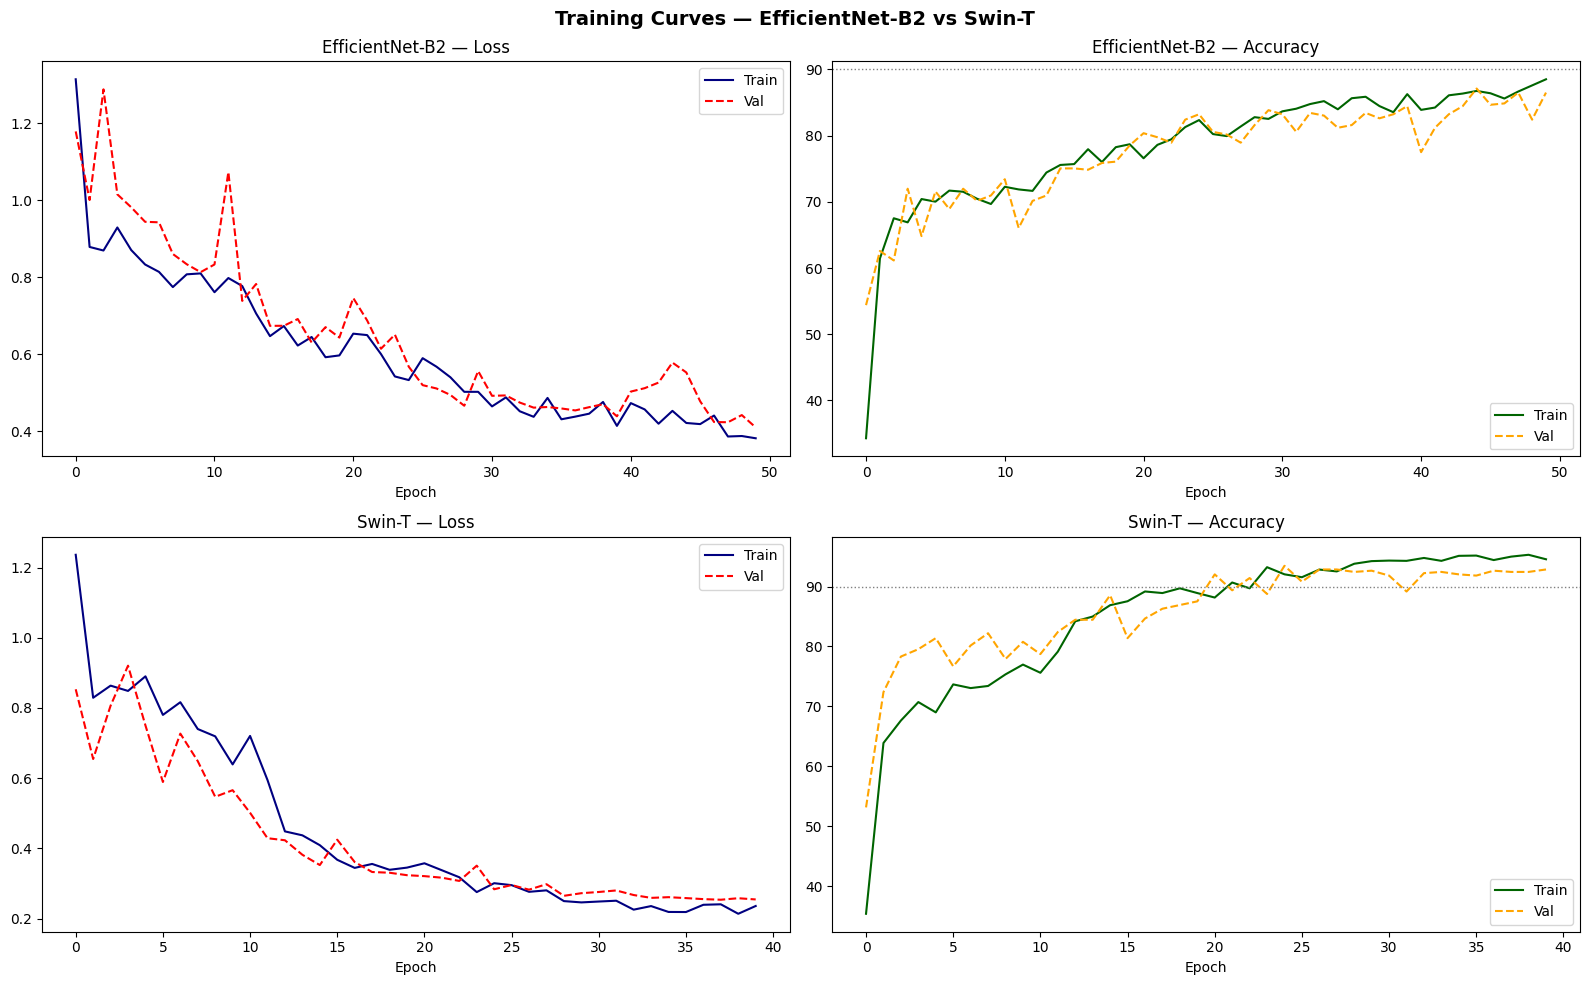

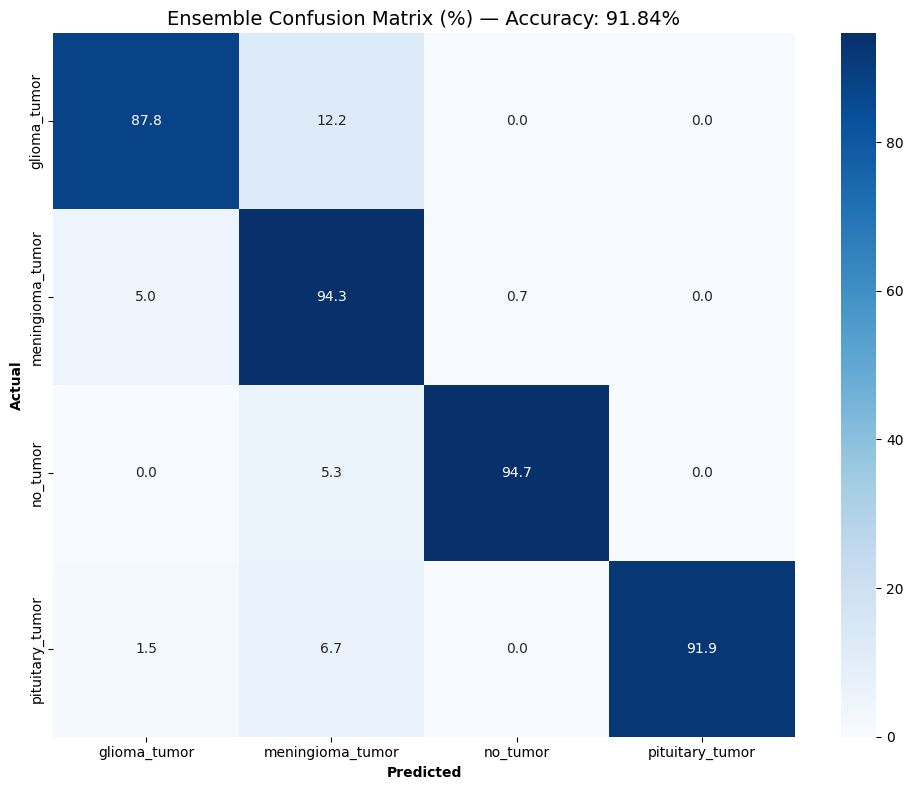


📊 Per-class recall:
  ✅ glioma_tumor           recall = 87.8%
  ✅ meningioma_tumor       recall = 94.3%
  ✅ no_tumor               recall = 94.7%
  ✅ pituitary_tumor        recall = 91.9%


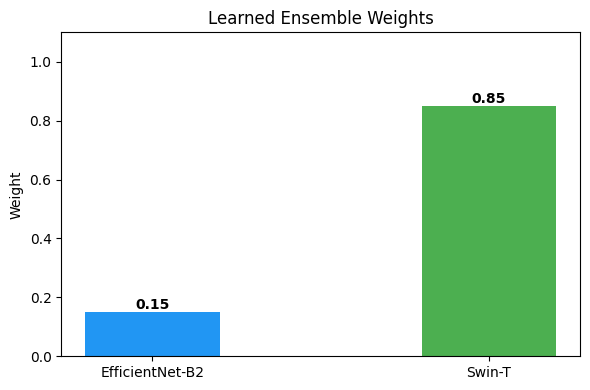

In [ ]:
#8
# ── Training curves for both models ───────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0,0].plot(eff_losses_t, label='Train', color='navy')
axes[0,0].plot(eff_losses_v, label='Val',   color='red', linestyle='--')
axes[0,0].set_title('EfficientNet-B2 — Loss')
axes[0,0].legend(); axes[0,0].set_xlabel('Epoch')

axes[0,1].plot(eff_accs_t, label='Train', color='darkgreen')
axes[0,1].plot(eff_accs_v, label='Val',   color='orange', linestyle='--')
axes[0,1].axhline(y=90, color='gray', linestyle=':', linewidth=1)
axes[0,1].set_title('EfficientNet-B2 — Accuracy')
axes[0,1].legend(); axes[0,1].set_xlabel('Epoch')

axes[1,0].plot(swin_losses_t, label='Train', color='navy')
axes[1,0].plot(swin_losses_v, label='Val',   color='red', linestyle='--')
axes[1,0].set_title('Swin-T — Loss')
axes[1,0].legend(); axes[1,0].set_xlabel('Epoch')

axes[1,1].plot(swin_accs_t, label='Train', color='darkgreen')
axes[1,1].plot(swin_accs_v, label='Val',   color='orange', linestyle='--')
axes[1,1].axhline(y=90, color='gray', linestyle=':', linewidth=1)
axes[1,1].set_title('Swin-T — Accuracy')
axes[1,1].legend(); axes[1,1].set_xlabel('Epoch')

plt.suptitle('Training Curves — EfficientNet-B2 vs Swin-T', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('training_curves_ensemble.png', dpi=150)
plt.show()

# ── Confusion matrix (0 to 100 Range) ─────────────────────────────────────────
cm      = confusion_matrix(y_true, y_pred)
# Changed normalization to multiply by 100
cm_norm = (cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]) * 100

plt.figure(figsize=(10, 8))
# fmt='.1f' is used for a cleaner percentage look
sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=merged_aug.classes,
            yticklabels=merged_aug.classes)
plt.title(f'Ensemble Confusion Matrix (%) — Accuracy: {final_acc:.2f}%', fontsize=14)
plt.ylabel('Actual',    fontweight='bold')
plt.xlabel('Predicted', fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix_ensemble.png', dpi=150)
plt.show()

# ── Per-class recall summary (0 to 100 Range) ─────────────────────────────────
print("\n📊 Per-class recall:")
for i, cls in enumerate(merged_aug.classes):
    r = cm_norm[i, i]
    # Adjusted threshold logic to 85.0 to match the 0-100 scale
    print(f"  {'✅' if r >= 85.0 else '⚠️ '} {cls:<22} recall = {r:.1f}%")

# ── Ensemble weight visualization ─────────────────────────────────────────────
weights = [best_w, 1-best_w]
labels  = ['EfficientNet-B2', 'Swin-T']
colors  = ['#2196F3', '#4CAF50']

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, weights, color=colors, width=0.4)
for bar, w in zip(bars, weights):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{w:.2f}', ha='center', fontweight='bold')
plt.title('Learned Ensemble Weights')
plt.ylabel('Weight')
plt.ylim(0, 1.1)
plt.tight_layout()
plt.show()

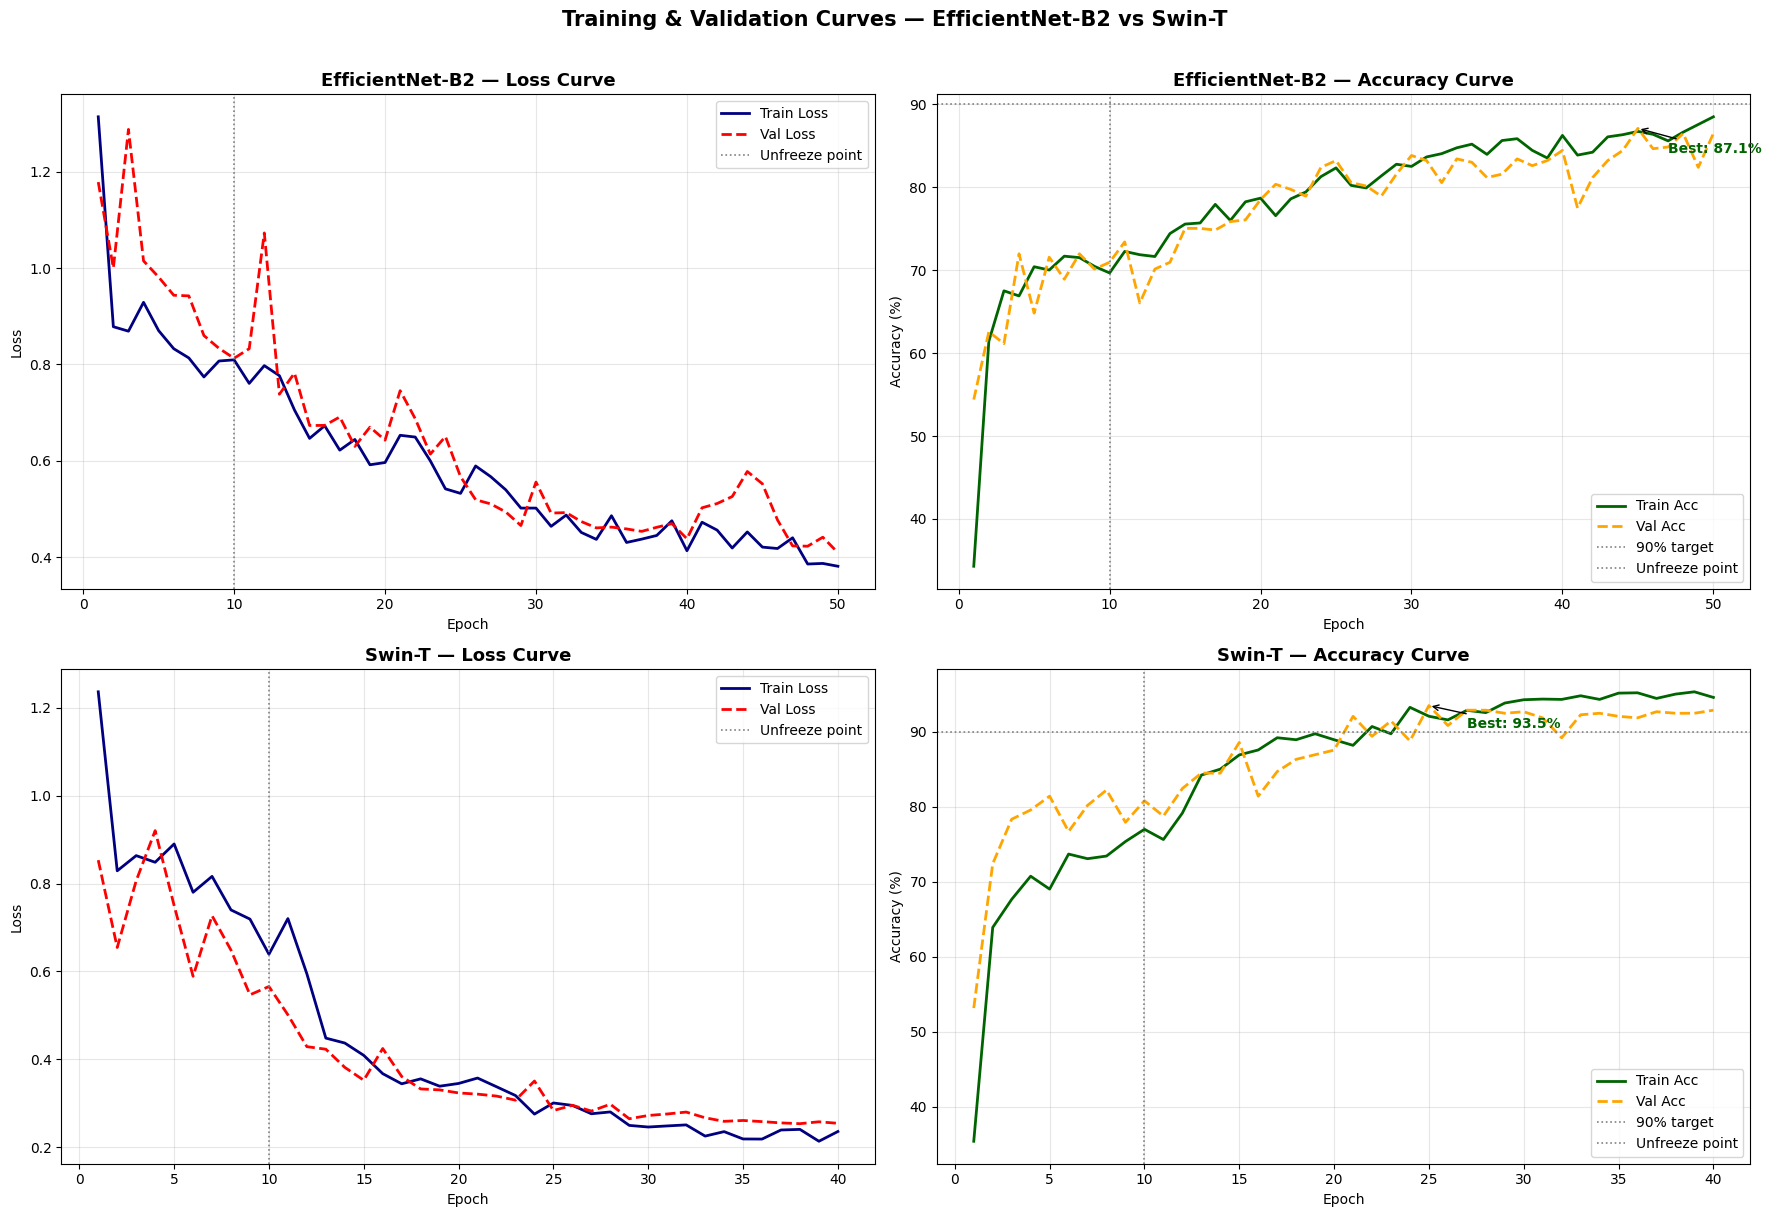


📊 Curve Summary:
  EfficientNet-B2 | Best Val Acc: 87.12% at epoch 45
  Swin-T          | Best Val Acc: 93.46% at epoch 25
  Train/Val gap   | EfficientNet: 2.0%  Swin-T: 1.7%


In [ ]:
#9
# ── Training & Validation Curves — Loss and Accuracy ──────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

epochs_eff  = range(1, len(eff_losses_t) + 1)
epochs_swin = range(1, len(swin_losses_t) + 1)

# ── EfficientNet Loss ──────────────────────────────────────────────────────────
axes[0, 0].plot(epochs_eff, eff_losses_t, label='Train Loss',
                color='navy', linewidth=2)
axes[0, 0].plot(epochs_eff, eff_losses_v, label='Val Loss',
                color='red', linestyle='--', linewidth=2)
axes[0, 0].axvline(x=10, color='gray', linestyle=':', linewidth=1.2,
                   label='Unfreeze point')
axes[0, 0].set_title('EfficientNet-B2 — Loss Curve', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Epoch'); axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend(); axes[0, 0].grid(alpha=0.3)

# ── EfficientNet Accuracy ──────────────────────────────────────────────────────
axes[0, 1].plot(epochs_eff, eff_accs_t, label='Train Acc',
                color='darkgreen', linewidth=2)
axes[0, 1].plot(epochs_eff, eff_accs_v, label='Val Acc',
                color='orange', linestyle='--', linewidth=2)
axes[0, 1].axhline(y=90, color='gray', linestyle=':', linewidth=1.2,
                   label='90% target')
axes[0, 1].axvline(x=10, color='gray', linestyle=':', linewidth=1.2,
                   label='Unfreeze point')
axes[0, 1].set_title('EfficientNet-B2 — Accuracy Curve', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Epoch'); axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].legend(); axes[0, 1].grid(alpha=0.3)

# Annotate best val acc
best_eff_epoch = int(np.argmax(eff_accs_v)) + 1
best_eff_acc   = max(eff_accs_v)
axes[0, 1].annotate(f'Best: {best_eff_acc:.1f}%',
                    xy=(best_eff_epoch, best_eff_acc),
                    xytext=(best_eff_epoch + 2, best_eff_acc - 3),
                    arrowprops=dict(arrowstyle='->', color='black'),
                    fontsize=10, color='darkgreen', fontweight='bold')

# ── Swin-T Loss ────────────────────────────────────────────────────────────────
axes[1, 0].plot(epochs_swin, swin_losses_t, label='Train Loss',
                color='navy', linewidth=2)
axes[1, 0].plot(epochs_swin, swin_losses_v, label='Val Loss',
                color='red', linestyle='--', linewidth=2)
axes[1, 0].axvline(x=10, color='gray', linestyle=':', linewidth=1.2,
                   label='Unfreeze point')
axes[1, 0].set_title('Swin-T — Loss Curve', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Epoch'); axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend(); axes[1, 0].grid(alpha=0.3)

# ── Swin-T Accuracy ────────────────────────────────────────────────────────────
axes[1, 1].plot(epochs_swin, swin_accs_t, label='Train Acc',
                color='darkgreen', linewidth=2)
axes[1, 1].plot(epochs_swin, swin_accs_v, label='Val Acc',
                color='orange', linestyle='--', linewidth=2)
axes[1, 1].axhline(y=90, color='gray', linestyle=':', linewidth=1.2,
                   label='90% target')
axes[1, 1].axvline(x=10, color='gray', linestyle=':', linewidth=1.2,
                   label='Unfreeze point')
axes[1, 1].set_title('Swin-T — Accuracy Curve', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Epoch'); axes[1, 1].set_ylabel('Accuracy (%)')
axes[1, 1].legend(); axes[1, 1].grid(alpha=0.3)

# Annotate best val acc
best_swin_epoch = int(np.argmax(swin_accs_v)) + 1
best_swin_acc   = max(swin_accs_v)
axes[1, 1].annotate(f'Best: {best_swin_acc:.1f}%',
                    xy=(best_swin_epoch, best_swin_acc),
                    xytext=(best_swin_epoch + 2, best_swin_acc - 3),
                    arrowprops=dict(arrowstyle='->', color='black'),
                    fontsize=10, color='darkgreen', fontweight='bold')

plt.suptitle('Training & Validation Curves — EfficientNet-B2 vs Swin-T',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('full_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary stats ──────────────────────────────────────────────────────────────
print("\n📊 Curve Summary:")
print(f"  EfficientNet-B2 | Best Val Acc: {best_eff_acc:.2f}% at epoch {best_eff_epoch}")
print(f"  Swin-T          | Best Val Acc: {best_swin_acc:.2f}% at epoch {best_swin_epoch}")
print(f"  Train/Val gap   | EfficientNet: "
      f"{eff_accs_t[-1] - eff_accs_v[-1]:.1f}%  "
      f"Swin-T: {swin_accs_t[-1] - swin_accs_v[-1]:.1f}%")

In [ ]:
#10
# ── Install dependencies ───────────────────────────────────────────────────────
try:
    import cv2
    from PIL import Image
    import matplotlib.patches as mpatches
    from matplotlib.gridspec import GridSpec
    from matplotlib.colors import LinearSegmentedColormap
    import matplotlib.patheffects as pe
    print("✅ Dependencies ready")
except ImportError:
    os.system("pip install opencv-python-headless -q")
    import cv2
    from PIL import Image
    import matplotlib.patches as mpatches
    from matplotlib.gridspec import GridSpec
    from matplotlib.colors import LinearSegmentedColormap
    import matplotlib.patheffects as pe

# ══════════════════════════════════════════════════════════════════════════════
# GRADCAM ENGINE
# ══════════════════════════════════════════════════════════════════════════════

class GradCAM:
    """
    Gradient-weighted Class Activation Mapping.
    Works for both EfficientNet (conv layers) and Swin-T (attention layers).
    """
    def __init__(self, model, target_layer):
        self.model        = model
        self.target_layer = target_layer
        self.gradients    = None
        self.activations  = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_full_backward_hook(backward_hook)

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        input_tensor = input_tensor.clone().requires_grad_(True)

        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()

        self.model.zero_grad()
        score = output[0, class_idx]
        score.backward()

        # Pool gradients across channels
        if self.gradients.dim() == 4:
            # CNN: (B, C, H, W)
            weights = self.gradients.mean(dim=[2, 3], keepdim=True)
            cam     = (weights * self.activations).sum(dim=1).squeeze()
        else:
            # Transformer: (B, seq_len, C) → reshape to spatial
            grad = self.gradients.mean(dim=-1).squeeze()
            act  = self.activations.mean(dim=-1).squeeze()
            cam  = grad * act
            h = w = int(cam.shape[0] ** 0.5)
            cam = cam[:h*w].reshape(h, w)

        cam = torch.relu(cam)
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.cpu().numpy(), class_idx, torch.softmax(output, dim=1)[0].detach().cpu().numpy()


def get_gradcam_targets(model, model_type='efficientnet'):
    """Return the best target layer for GradCAM for each model type."""
    if model_type == 'efficientnet':
        return model.features[-1]   # Last convolutional block
    else:
        return model.features[-1]   # Last Swin stage


def overlay_gradcam(img_tensor, cam, alpha=0.5):
    """
    Overlay GradCAM heatmap onto original image.
    Returns PIL image with heatmap overlay.
    """
    # Denormalize image
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img  = img_tensor.squeeze().cpu() * std + mean
    img  = img.permute(1, 2, 0).numpy()
    img  = np.clip(img, 0, 1)

    # Resize CAM to image size
    cam_resized = cv2.resize(cam, (img.shape[1], img.shape[0]))
    cam_resized = np.clip(cam_resized, 0, 1)

    # Apply custom medical heatmap (black→blue→cyan→yellow→red)
    medical_cmap = LinearSegmentedColormap.from_list(
        'medical', ['#000033', '#0000FF', '#00FFFF', '#FFFF00', '#FF0000']
    )
    heatmap = medical_cmap(cam_resized)[:, :, :3]

    # Blend
    overlay = alpha * heatmap + (1 - alpha) * img
    overlay = np.clip(overlay, 0, 1)

    return img, cam_resized, overlay


def fused_gradcam(eff_cam, swin_cam, eff_weight, swin_weight):
    """
    Fuse GradCAM maps from both models using ensemble weights.
    This gives a more reliable localization than either model alone.
    """
    # Resize both to same size
    h, w   = 224, 224
    eff_r  = cv2.resize(eff_cam,  (w, h))
    swin_r = cv2.resize(swin_cam, (w, h))

    # Weighted fusion
    fused = eff_weight * eff_r + swin_weight * swin_r
    if fused.max() > 0:
        fused = fused / fused.max()
    return fused


# ══════════════════════════════════════════════════════════════════════════════
# CLINICAL REPORT GENERATOR
# ══════════════════════════════════════════════════════════════════════════════

CLASS_INFO = {
    'glioma_tumor': {
        'color'      : '#FF4444',
        'risk'       : 'HIGH RISK',
        'risk_color' : '#FF0000',
        'description': 'Gliomas are primary brain tumors arising from glial cells. '
                       'They account for ~30% of all brain tumors and ~80% of malignant tumors.',
        'recommendation': [
            'Immediate neurosurgical consultation recommended',
            'MRI with contrast enhancement for staging',
            'Biopsy for WHO grading (I-IV)',
            'Multidisciplinary tumor board review',
            'Consider surgery, radiation, and chemotherapy'
        ],
        'urgency': '⚠️  URGENT — Refer within 24–48 hours'
    },
    'meningioma_tumor': {
        'color'      : '#FF8C00',
        'risk'       : 'MODERATE RISK',
        'risk_color' : '#FF8C00',
        'description': 'Meningiomas arise from the meninges and are mostly benign (WHO Grade I). '
                       'They represent ~37% of all primary brain tumors.',
        'recommendation': [
            'Neurosurgical consultation within 1–2 weeks',
            'Follow-up MRI in 3–6 months if asymptomatic',
            'Monitor for symptom progression',
            'Consider surgical resection if symptomatic',
            'Radiation therapy for recurrent or atypical cases'
        ],
        'urgency': '📋 SEMI-URGENT — Refer within 1–2 weeks'
    },
    'no_tumor': {
        'color'      : '#00C853',
        'risk'       : 'NO PATHOLOGY',
        'risk_color' : '#00C853',
        'description': 'No significant intracranial mass lesion detected. '
                       'Normal brain parenchyma appearance within MRI resolution limits.',
        'recommendation': [
            'No immediate intervention required',
            'Correlate with clinical symptoms',
            'Routine follow-up as clinically indicated',
            'Repeat MRI if symptoms persist or worsen'
        ],
        'urgency': '✅ ROUTINE — No urgent referral needed'
    },
    'pituitary_tumor': {
        'color'      : '#7C4DFF',
        'risk'       : 'MODERATE RISK',
        'risk_color' : '#7C4DFF',
        'description': 'Pituitary adenomas account for ~15% of intracranial neoplasms. '
                       'Most are benign but may cause hormonal or visual disturbances.',
        'recommendation': [
            'Endocrinology consultation for hormonal workup',
            'Ophthalmology review for visual field testing',
            'Dedicated pituitary MRI protocol',
            'Consider transsphenoidal surgery if indicated',
            'Medical management for secreting adenomas'
        ],
        'urgency': '📋 SEMI-URGENT — Refer within 1–2 weeks'
    }
}


def generate_clinical_report(img_tensor, scan_id, patient_id=None):
    """
    Full clinical report with:
    - Original scan
    - EfficientNet GradCAM
    - Swin-T GradCAM
    - Fused GradCAM (unique feature)
    - Confidence bars
    - Clinical recommendations
    """
    classes = merged_aug.classes

    # ── GradCAM for EfficientNet ───────────────────────────────────────────────
    gc_eff  = GradCAM(eff_model,  get_gradcam_targets(eff_model,  'efficientnet'))
    gc_swin = GradCAM(swin_model, get_gradcam_targets(swin_model, 'swin'))

    inp = img_tensor.unsqueeze(0).to(device)

    eff_cam,  eff_pred,  eff_probs  = gc_eff.generate(inp)
    swin_cam, swin_pred, swin_probs = gc_swin.generate(inp)

    # Ensemble probabilities
    ens_probs   = best_w * eff_probs + (1-best_w) * swin_probs
    final_pred  = ens_probs.argmax()
    confidence  = ens_probs[final_pred] * 100
    pred_class  = classes[final_pred]
    info        = CLASS_INFO[pred_class]

    # Fused GradCAM
    fused_cam = fused_gradcam(eff_cam, swin_cam, best_w, 1-best_w)

    # Overlays
    orig,  _,         eff_overlay   = overlay_gradcam(img_tensor, eff_cam,   alpha=0.55)
    _,     _,         swin_overlay  = overlay_gradcam(img_tensor, swin_cam,  alpha=0.55)
    _,     fused_map, fused_overlay = overlay_gradcam(img_tensor, fused_cam, alpha=0.55)

    # ── Figure layout ──────────────────────────────────────────────────────────
    fig = plt.figure(figsize=(20, 24), facecolor='#0A0A0F')
    gs  = GridSpec(4, 4, figure=fig, hspace=0.4, wspace=0.35,
                   top=0.93, bottom=0.04, left=0.05, right=0.97)

    # ── Header ────────────────────────────────────────────────────────────────
    ax_header = fig.add_subplot(gs[0, :])
    ax_header.set_facecolor('#0A0A0F')
    ax_header.axis('off')

    # Title bar
    header_box = mpatches.FancyBboxPatch(
        (0.0, 0.1), 1.0, 0.85,
        boxstyle="round,pad=0.02",
        facecolor='#12121A', edgecolor=info['color'], linewidth=2,
        transform=ax_header.transAxes
    )
    ax_header.add_patch(header_box)

    ax_header.text(0.5, 0.72,
                   'NEURO·SCAN AI — Clinical Diagnostic Report',
                   transform=ax_header.transAxes,
                   fontsize=18, fontweight='bold', color='white',
                   ha='center', va='center',
                   fontfamily='monospace')

    ax_header.text(0.5, 0.35,
                   f'Scan ID: {scan_id}   |   '
                   f'Patient: {patient_id or "ANON-" + str(scan_id).zfill(4)}   |   '
                   f'Model: EfficientNet-B2 ⊕ Swin-T Ensemble   |   '
                   f'TTA: 4-way',
                   transform=ax_header.transAxes,
                   fontsize=9, color='#888888',
                   ha='center', va='center',
                   fontfamily='monospace')

    # ── Scan images row ────────────────────────────────────────────────────────
    titles    = ['Original MRI', 'EfficientNet-B2\nGradCAM',
                 'Swin-T\nGradCAM', 'Fused Ensemble\nGradCAM ★']
    overlays  = [orig, eff_overlay, swin_overlay, fused_overlay]
    subtitles = ['Raw Input', f'Pred: {classes[eff_pred]}',
                 f'Pred: {classes[swin_pred]}', f'Ensemble Pred: {pred_class}']

    for col, (title, img_show, sub) in enumerate(zip(titles, overlays, subtitles)):
        ax = fig.add_subplot(gs[1, col])
        ax.imshow(img_show)
        ax.set_title(title, color='white', fontsize=10,
                     fontweight='bold', fontfamily='monospace', pad=8)
        ax.set_xlabel(sub, color='#AAAAAA', fontsize=8, fontfamily='monospace')
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(info['color'] if col == 3 else '#333333')
            spine.set_linewidth(2 if col == 3 else 1)

        # Add ★ badge on fused panel
        if col == 3:
            ax.text(0.97, 0.97, '★ FUSED', transform=ax.transAxes,
                    fontsize=7, color=info['color'], ha='right', va='top',
                    fontfamily='monospace', fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2',
                              facecolor='#0A0A0F', edgecolor=info['color'], alpha=0.8))

    # ── Colorbar for heatmap ───────────────────────────────────────────────────
    ax_cb = fig.add_axes([0.92, 0.54, 0.015, 0.18])
    medical_cmap = LinearSegmentedColormap.from_list(
        'medical', ['#000033', '#0000FF', '#00FFFF', '#FFFF00', '#FF0000']
    )
    cb = plt.colorbar(
        plt.cm.ScalarMappable(cmap=medical_cmap),
        cax=ax_cb
    )
    cb.set_label('Activation', color='white', fontsize=8)
    cb.ax.yaxis.set_tick_params(color='white')
    plt.setp(cb.ax.yaxis.get_ticklabels(), color='white', fontsize=7)

    # ── Confidence panel ───────────────────────────────────────────────────────
    ax_conf = fig.add_subplot(gs[2, :2])
    ax_conf.set_facecolor('#12121A')
    ax_conf.set_title('Ensemble Confidence Scores',
                       color='white', fontsize=11,
                       fontweight='bold', fontfamily='monospace', pad=10)

    bar_colors = [CLASS_INFO[c]['color'] for c in classes]
    bars = ax_conf.barh(classes, ens_probs * 100,
                        color=bar_colors, height=0.5, alpha=0.85)

    # Highlight predicted class
    bars[final_pred].set_alpha(1.0)
    bars[final_pred].set_edgecolor('white')
    bars[final_pred].set_linewidth(2)

    for bar, prob in zip(bars, ens_probs):
        ax_conf.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                     f'{prob*100:.1f}%',
                     va='center', color='white', fontsize=9, fontfamily='monospace')

    ax_conf.set_xlim(0, 115)
    ax_conf.set_xlabel('Confidence (%)', color='#888888', fontsize=9)
    ax_conf.tick_params(colors='white')
    for spine in ax_conf.spines.values():
        spine.set_edgecolor('#333333')
    ax_conf.xaxis.label.set_color('#888888')
    [t.set_color('white') for t in ax_conf.get_yticklabels()]
    [t.set_color('#888888') for t in ax_conf.get_xticklabels()]

    # ── Model agreement panel ──────────────────────────────────────────────────
    ax_agree = fig.add_subplot(gs[2, 2:])
    ax_agree.set_facecolor('#12121A')
    ax_agree.set_title('Model Agreement Analysis',
                        color='white', fontsize=11,
                        fontweight='bold', fontfamily='monospace', pad=10)

    x      = np.arange(len(classes))
    width  = 0.35
    b1 = ax_agree.bar(x - width/2, eff_probs  * 100, width,
                       label='EfficientNet-B2', color='#2196F3', alpha=0.8)
    b2 = ax_agree.bar(x + width/2, swin_probs * 100, width,
                       label='Swin-T',          color='#4CAF50', alpha=0.8)

    ax_agree.set_xticks(x)
    ax_agree.set_xticklabels([c.replace('_tumor','').replace('_',' ').title()
                               for c in classes],
                              color='white', fontsize=8, fontfamily='monospace')
    ax_agree.set_ylabel('Confidence (%)', color='#888888', fontsize=9)
    ax_agree.legend(facecolor='#1E1E2E', edgecolor='#333333',
                    labelcolor='white', fontsize=8)
    ax_agree.set_facecolor('#12121A')
    for spine in ax_agree.spines.values():
        spine.set_edgecolor('#333333')
    [t.set_color('#888888') for t in ax_agree.get_yticklabels()]

    # Agreement score
    agreement = 1 - np.sum(np.abs(eff_probs - swin_probs)) / 2
    ax_agree.text(0.97, 0.95, f'Agreement: {agreement*100:.0f}%',
                  transform=ax_agree.transAxes,
                  fontsize=9, color='#00FF88', ha='right', va='top',
                  fontfamily='monospace',
                  bbox=dict(boxstyle='round,pad=0.3',
                            facecolor='#0A0A0F', edgecolor='#00FF88', alpha=0.8))

    # ── Clinical findings panel ────────────────────────────────────────────────
    ax_clin = fig.add_subplot(gs[3, :])
    ax_clin.set_facecolor('#12121A')
    ax_clin.axis('off')

    # Outer box
    outer = mpatches.FancyBboxPatch(
        (0.0, 0.0), 1.0, 1.0,
        boxstyle="round,pad=0.01",
        facecolor='#12121A', edgecolor=info['color'], linewidth=1.5,
        transform=ax_clin.transAxes
    )
    ax_clin.add_patch(outer)

    # Diagnosis badge
    ax_clin.text(0.02, 0.88,
                 f"DIAGNOSIS:  {pred_class.replace('_', ' ').upper()}",
                 transform=ax_clin.transAxes,
                 fontsize=13, fontweight='bold', color=info['color'],
                 fontfamily='monospace', va='top')

    ax_clin.text(0.02, 0.72,
                 f"Confidence: {confidence:.1f}%   |   Risk Level: {info['risk']}   |   {info['urgency']}",
                 transform=ax_clin.transAxes,
                 fontsize=9, color='white', fontfamily='monospace', va='top')

    ax_clin.text(0.02, 0.57,
                 f"Clinical Context:\n{info['description']}",
                 transform=ax_clin.transAxes,
                 fontsize=8.5, color='#CCCCCC', fontfamily='monospace',
                 va='top', wrap=True)

    ax_clin.text(0.52, 0.88, "Clinical Recommendations:",
                 transform=ax_clin.transAxes,
                 fontsize=10, fontweight='bold', color='white',
                 fontfamily='monospace', va='top')

    for i, rec in enumerate(info['recommendation']):
        ax_clin.text(0.52, 0.72 - i * 0.14,
                     f"  {'①②③④⑤'[i]}  {rec}",
                     transform=ax_clin.transAxes,
                     fontsize=8.5, color='#CCCCCC',
                     fontfamily='monospace', va='top')

    # Disclaimer
    ax_clin.text(0.5, 0.03,
                 '⚠  AI-ASSISTED ANALYSIS ONLY — NOT A SUBSTITUTE FOR PROFESSIONAL MEDICAL DIAGNOSIS',
                 transform=ax_clin.transAxes,
                 fontsize=7.5, color='#555555', ha='center', va='bottom',
                 fontfamily='monospace')

    plt.savefig(f'clinical_report_scan_{scan_id}.png',
                dpi=150, bbox_inches='tight',
                facecolor='#0A0A0F', edgecolor='none')
    plt.show()

    return {
        'scan_id'     : scan_id,
        'prediction'  : pred_class,
        'confidence'  : confidence,
        'eff_pred'    : classes[eff_pred],
        'swin_pred'   : classes[swin_pred],
        'agreement'   : agreement * 100,
        'ens_probs'   : ens_probs,
        'risk'        : info['risk']
    }

print("✅ GradCAM engine + Clinical Report generator ready")

✅ Dependencies ready
✅ GradCAM engine + Clinical Report generator ready


🏥 Generating Clinical Diagnostic Reports...


  Generating report: GLIOMA_TUMOR (confidence: 99.5%)


/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9314 (\N{CIRCLED DIGIT THREE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9315 (\N{CIRCLED DIGIT FOUR}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9316 (\N{CIRCLED DIGIT FIVE}) missing f

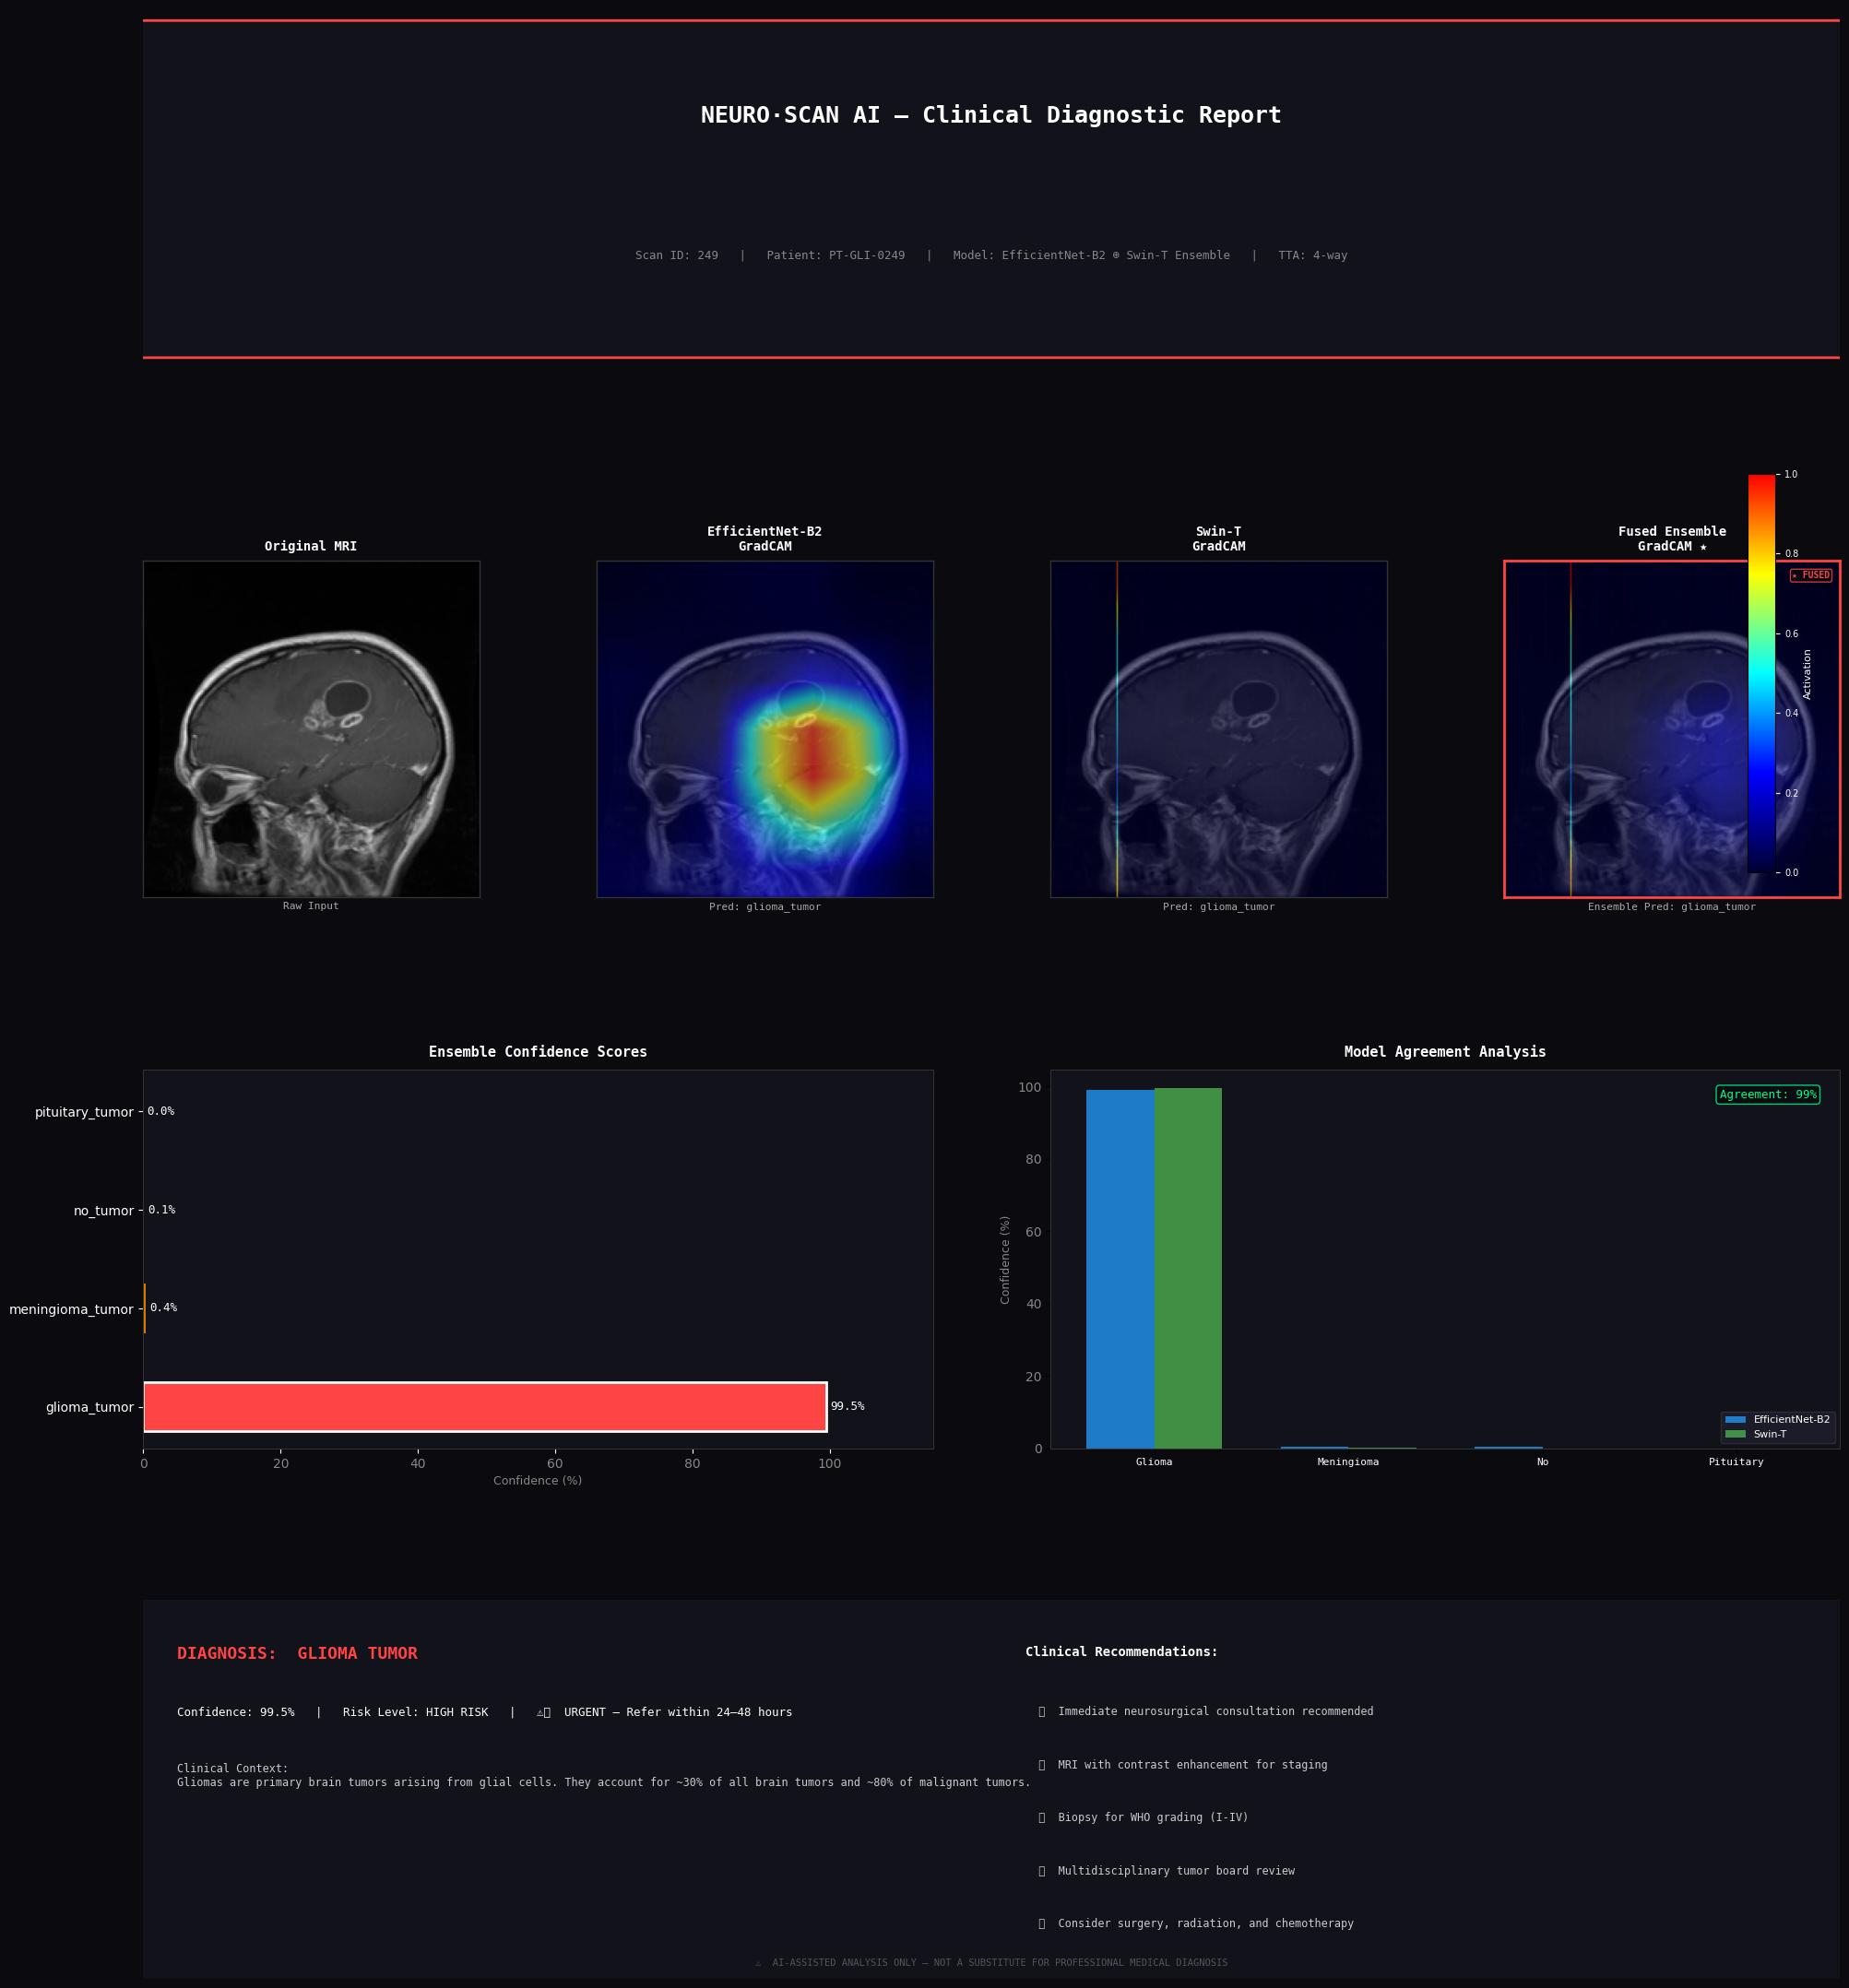


  Generating report: MENINGIOMA_TUMOR (confidence: 99.7%)


/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 128203 (\N{CLIPBOARD}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9314 (\N{CIRCLED DIGIT THREE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9315 (\N{CIRCLED DIGIT FOUR}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9316 (\N{CIRCLED DIGIT FIVE}) missing from font(s)

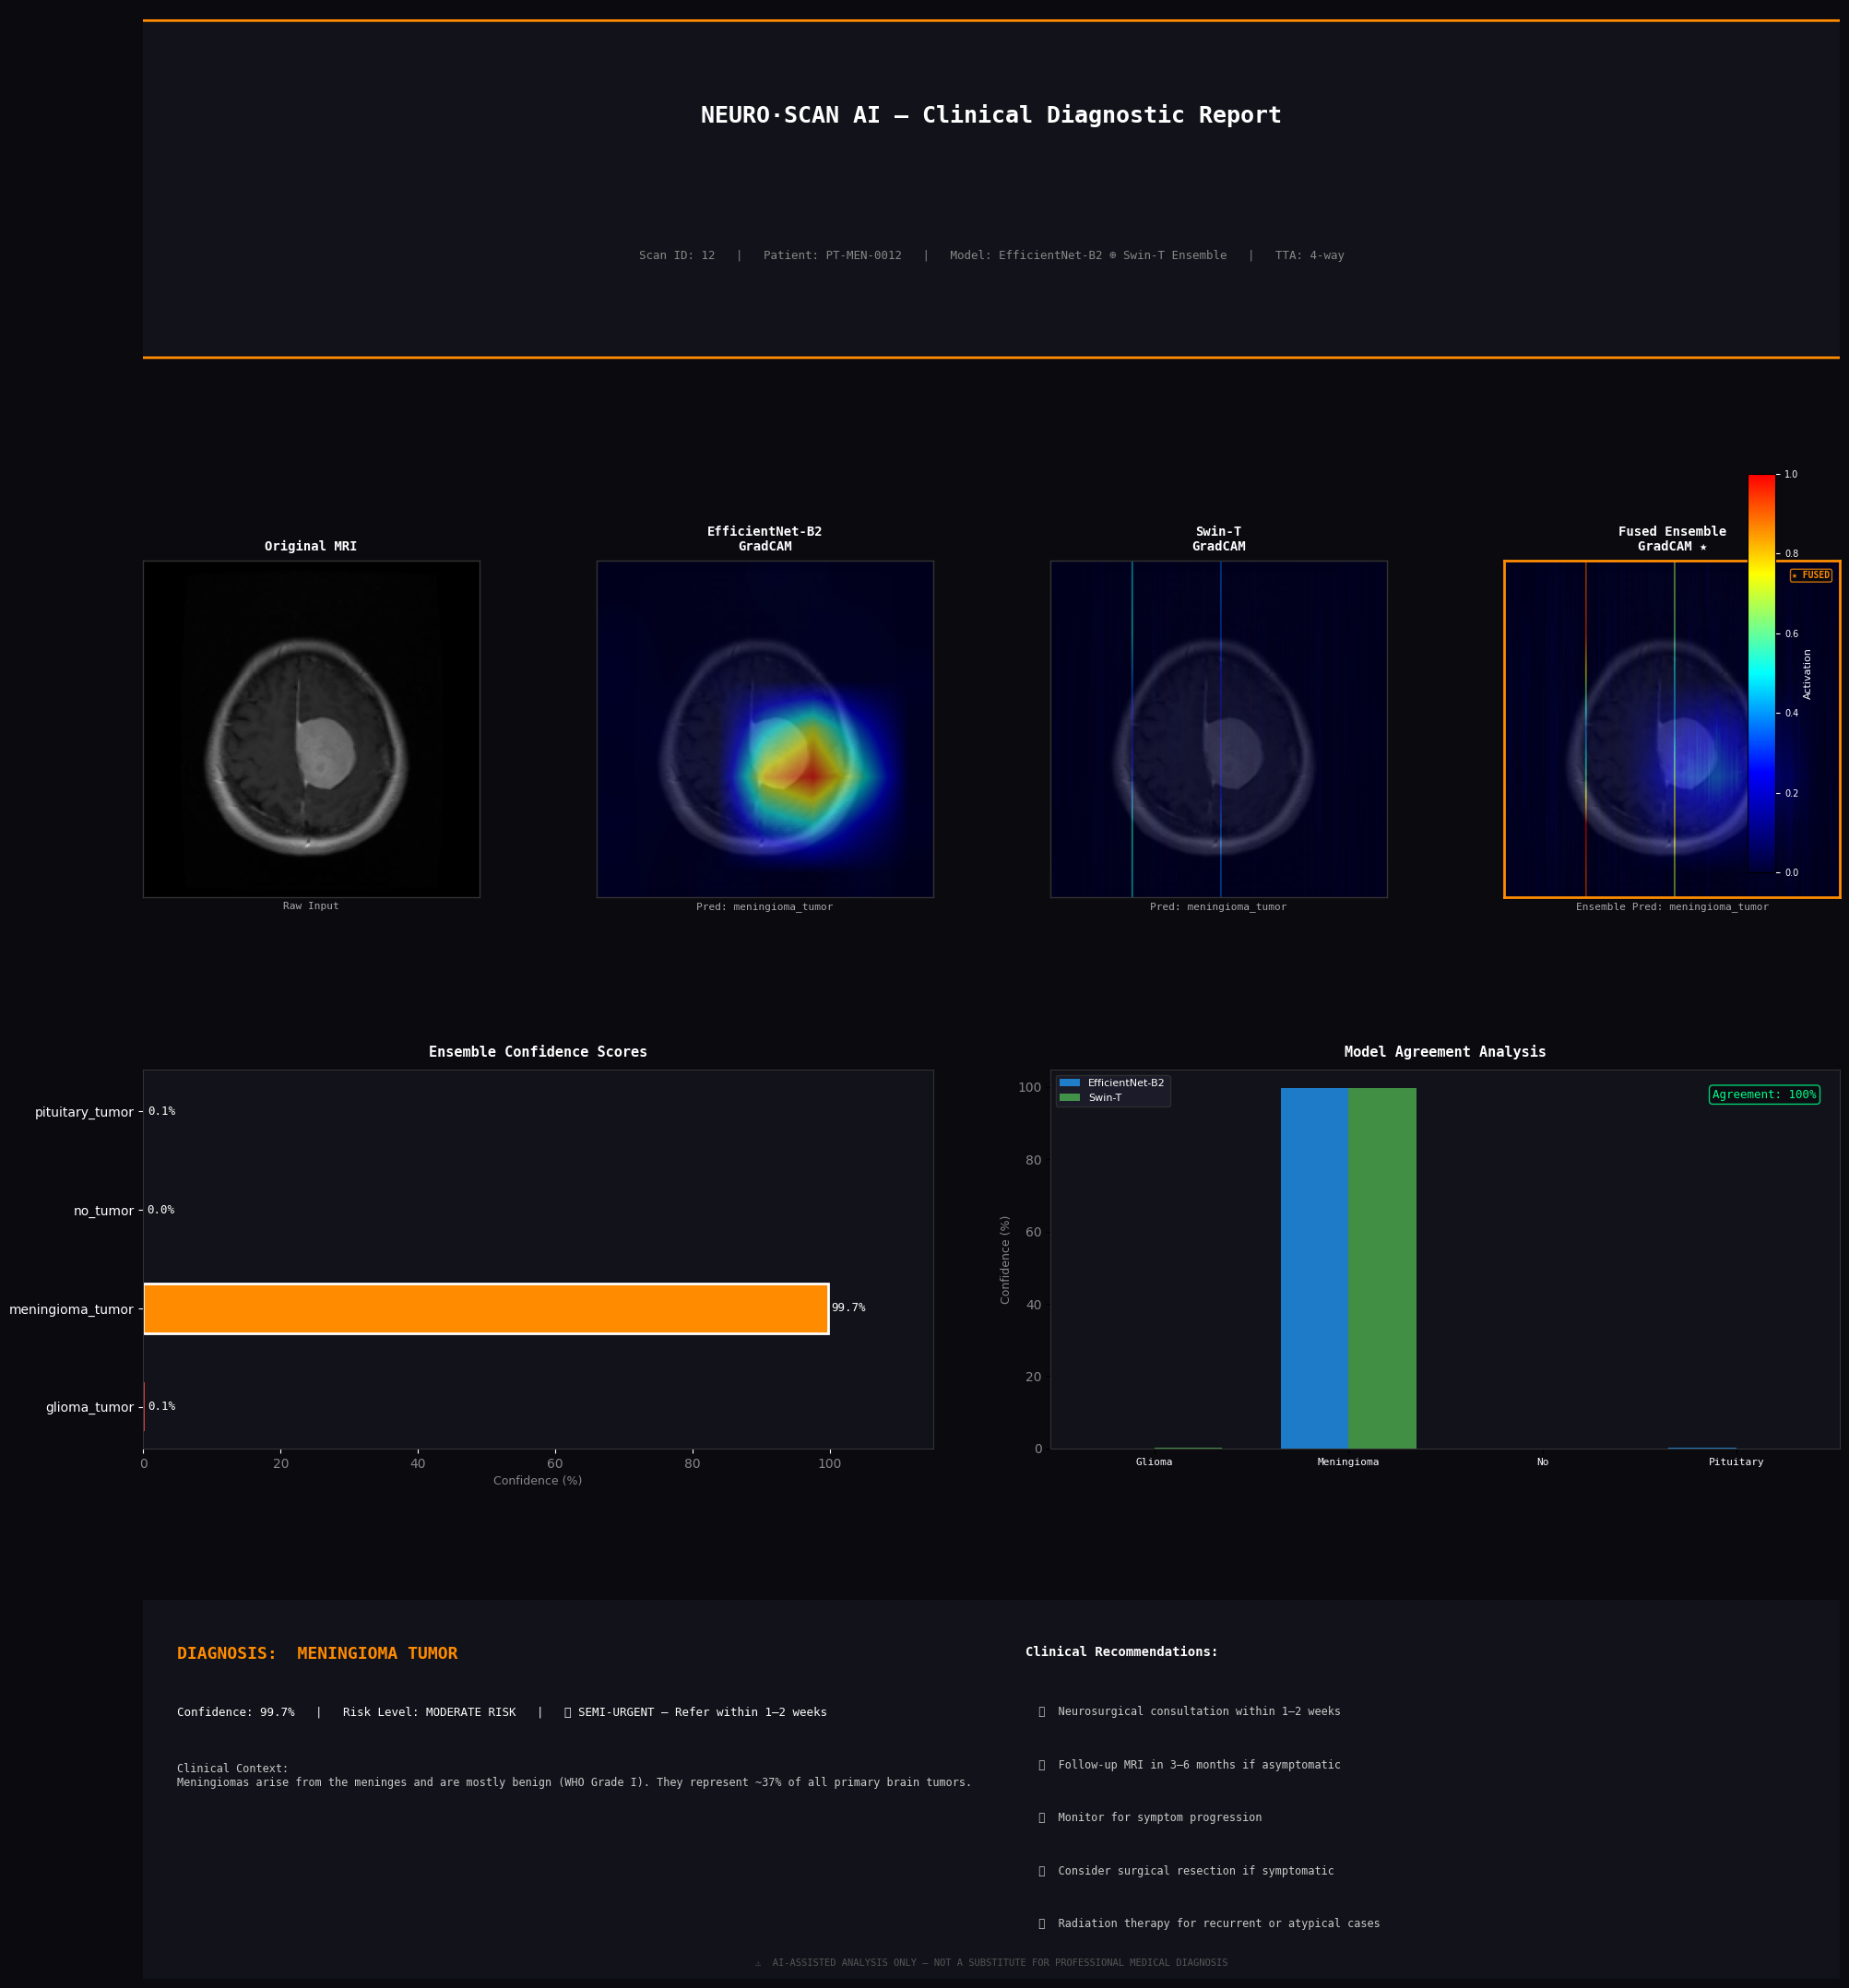


  Generating report: NO_TUMOR (confidence: 98.5%)


/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9314 (\N{CIRCLED DIGIT THREE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9315 (\N{CIRCLED DIGIT FOUR}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (

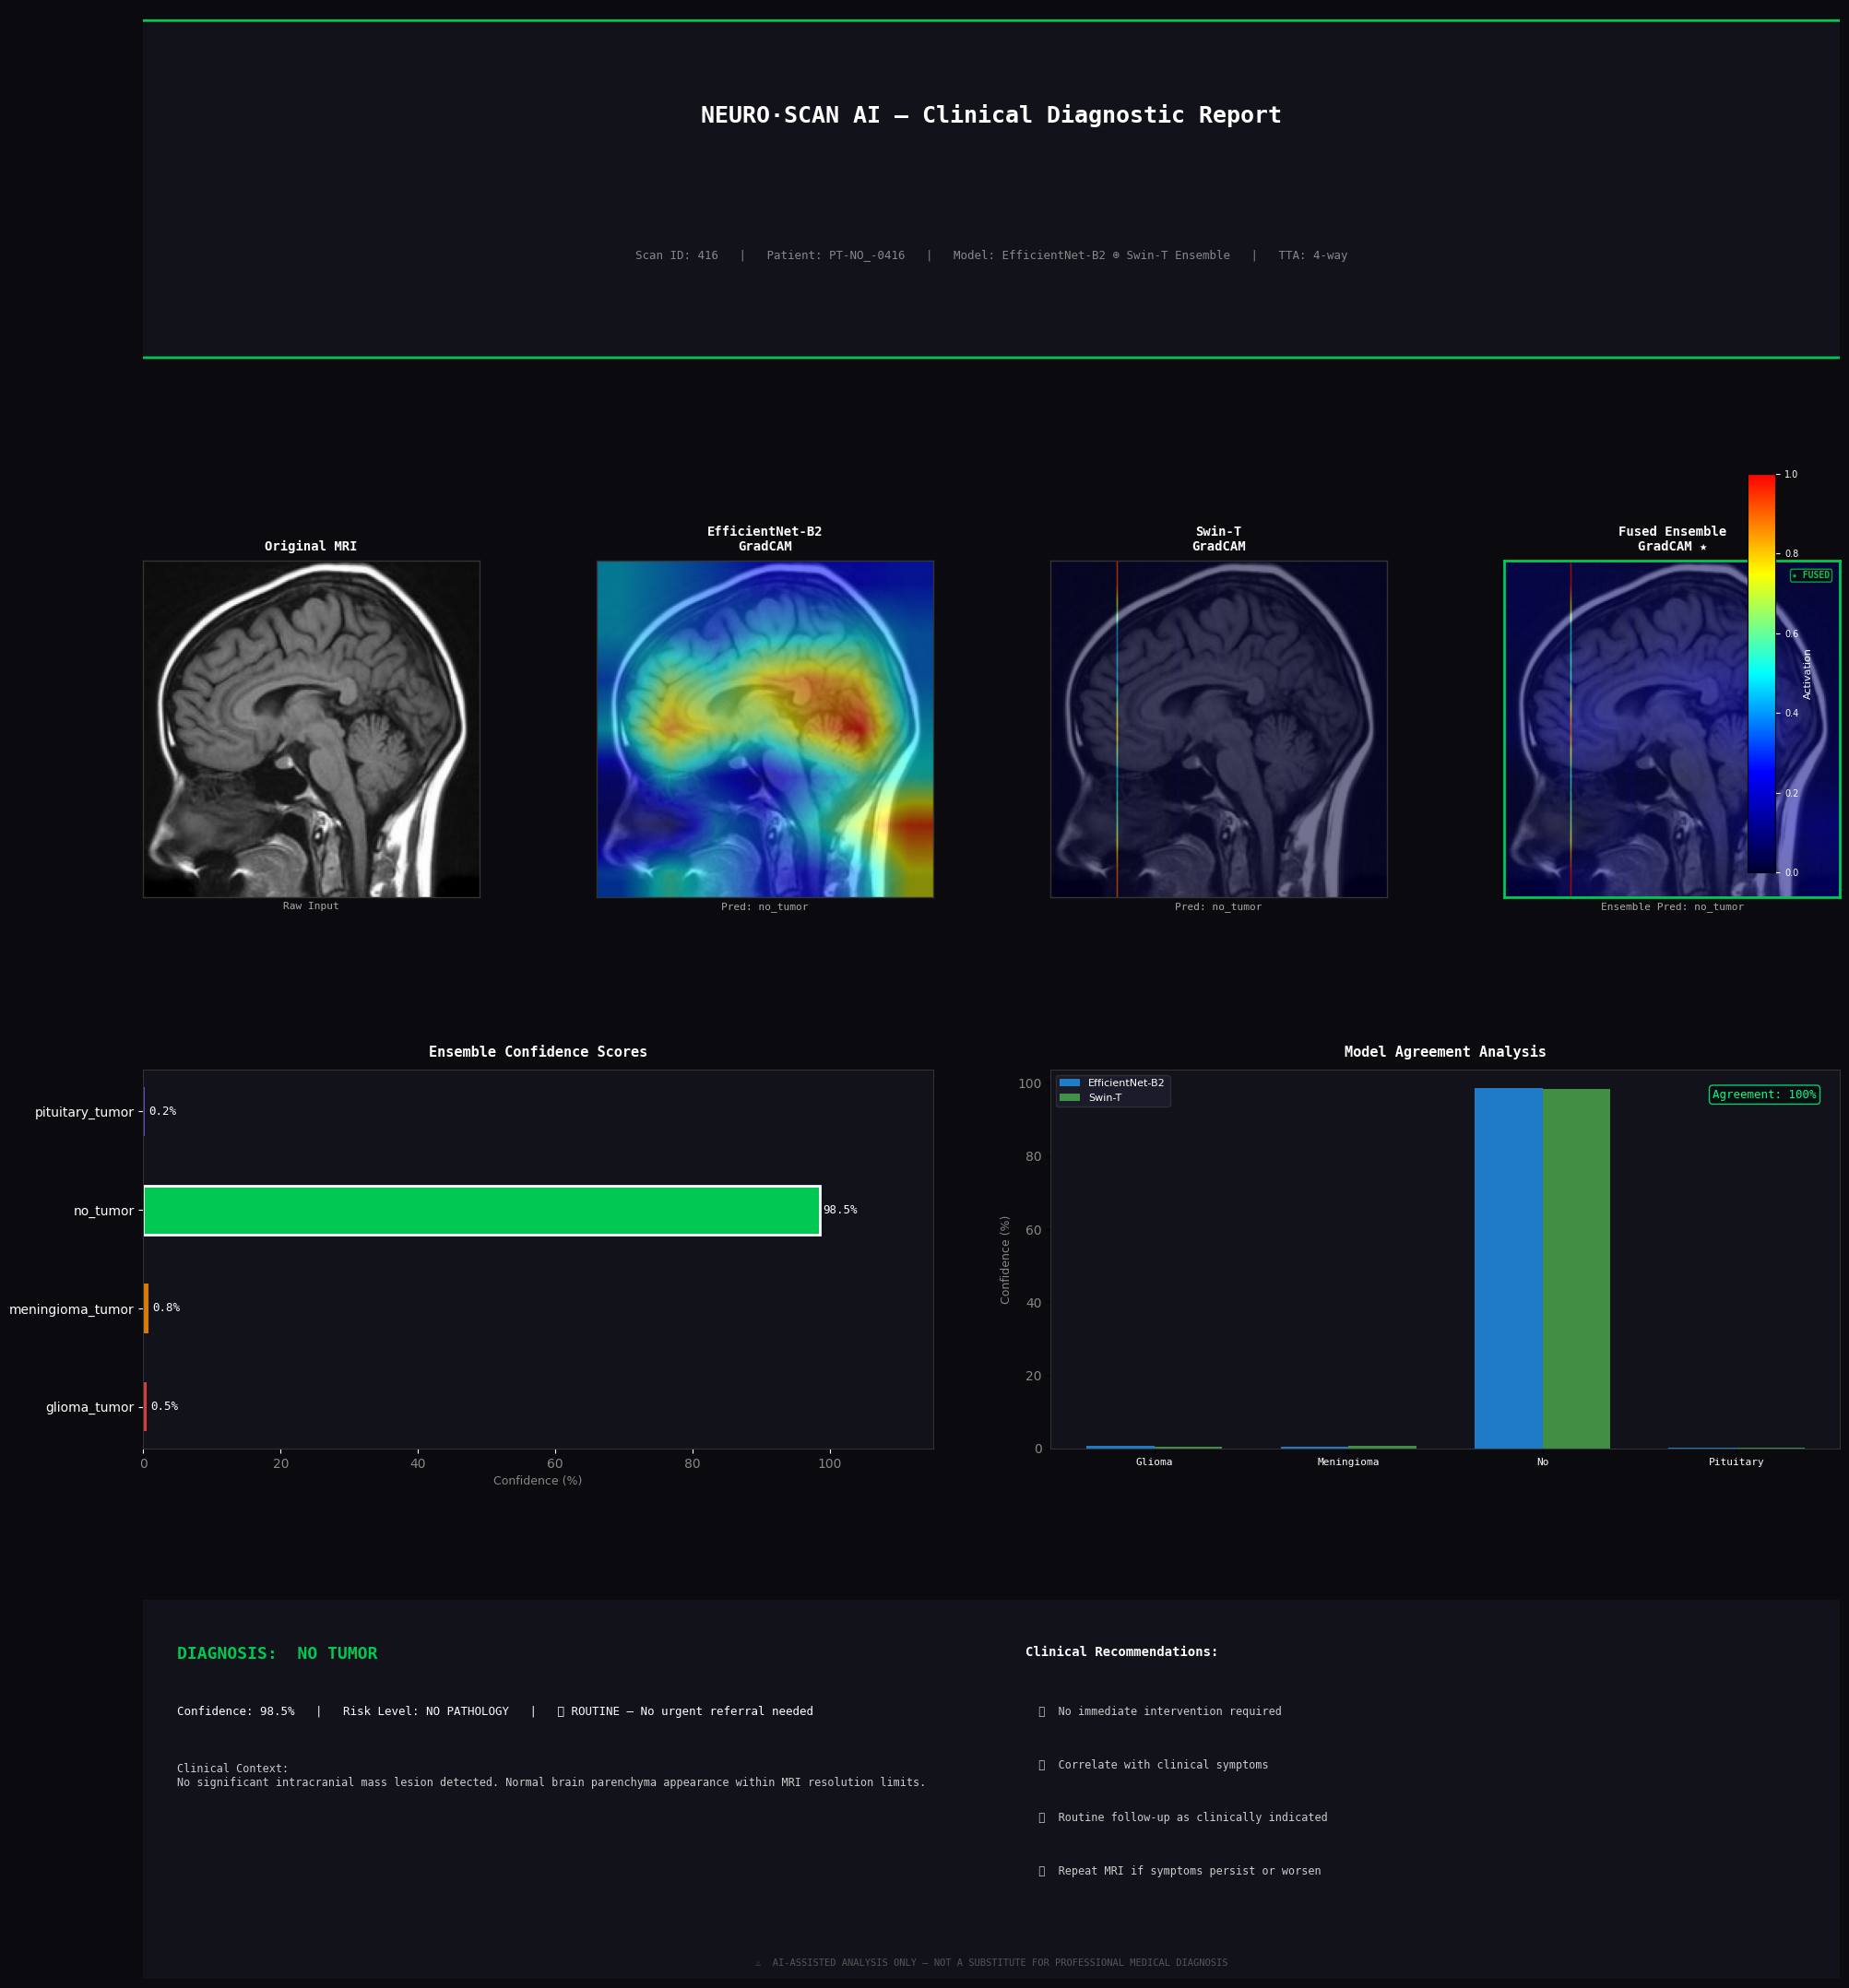


  Generating report: PITUITARY_TUMOR (confidence: 98.2%)


/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 128203 (\N{CLIPBOARD}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9314 (\N{CIRCLED DIGIT THREE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9315 (\N{CIRCLED DIGIT FOUR}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9316 (\N{CIRCLED DIGIT FIVE}) missing from font(s)

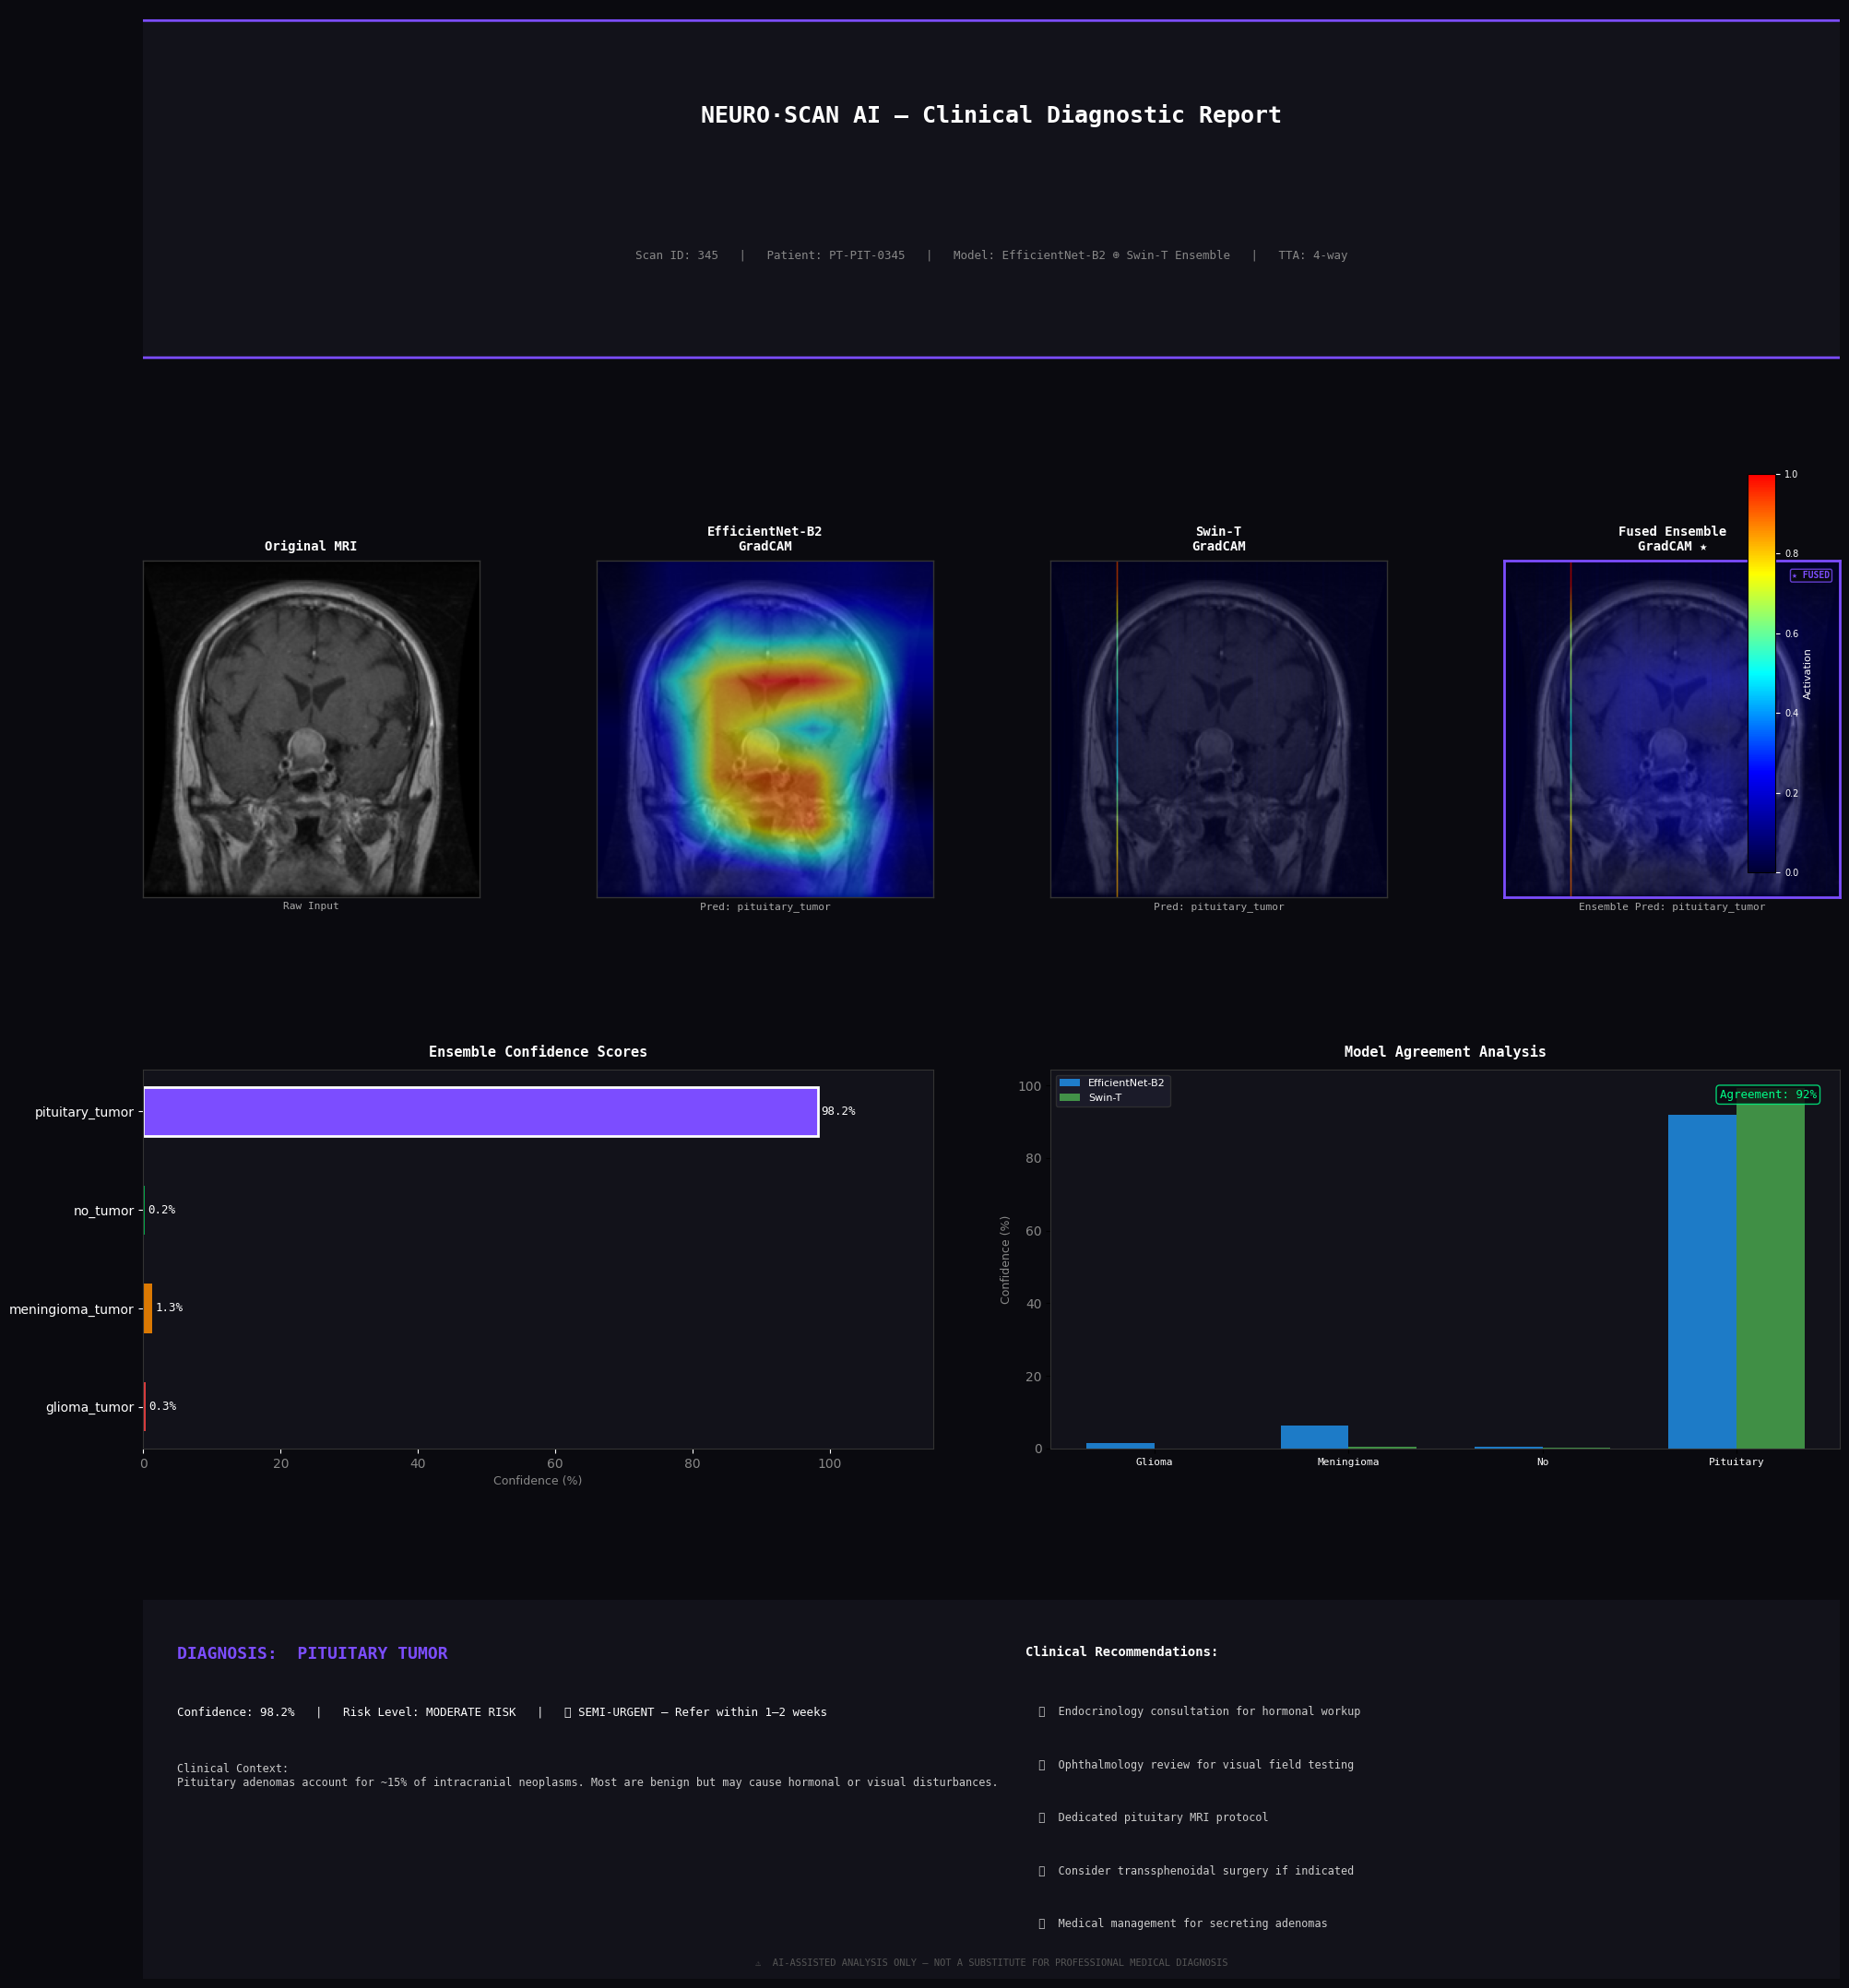


  CLINICAL REPORT SUMMARY
  Scan ID    True Class             Confidence   Agreement    Risk
----------------------------------------------------------------------
  249        glioma_tumor           99.5         99.4         HIGH RISK
  12         meningioma_tumor       99.7         99.9         MODERATE RISK
  416        no_tumor               98.5         99.7         NO PATHOLOGY
  345        pituitary_tumor        98.2         92.5         MODERATE RISK

🔍 Finding a case where EfficientNet and Swin-T DISAGREE...
  Found disagreement at scan index 14
  EfficientNet says : glioma_tumor
  Swin-T says       : meningioma_tumor
  True label        : meningioma_tumor

  Generating disagreement report...


/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 128203 (\N{CLIPBOARD}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9312 (\N{CIRCLED DIGIT ONE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9313 (\N{CIRCLED DIGIT TWO}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9314 (\N{CIRCLED DIGIT THREE}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9315 (\N{CIRCLED DIGIT FOUR}) missing from font(s) DejaVu Sans Mono.
  plt.savefig(f'clinical_report_scan_{scan_id}.png',
/tmp/ipykernel_2072/3928568390.py:425: UserWarning: Glyph 9316 (\N{CIRCLED DIGIT FIVE}) missing from font(s)

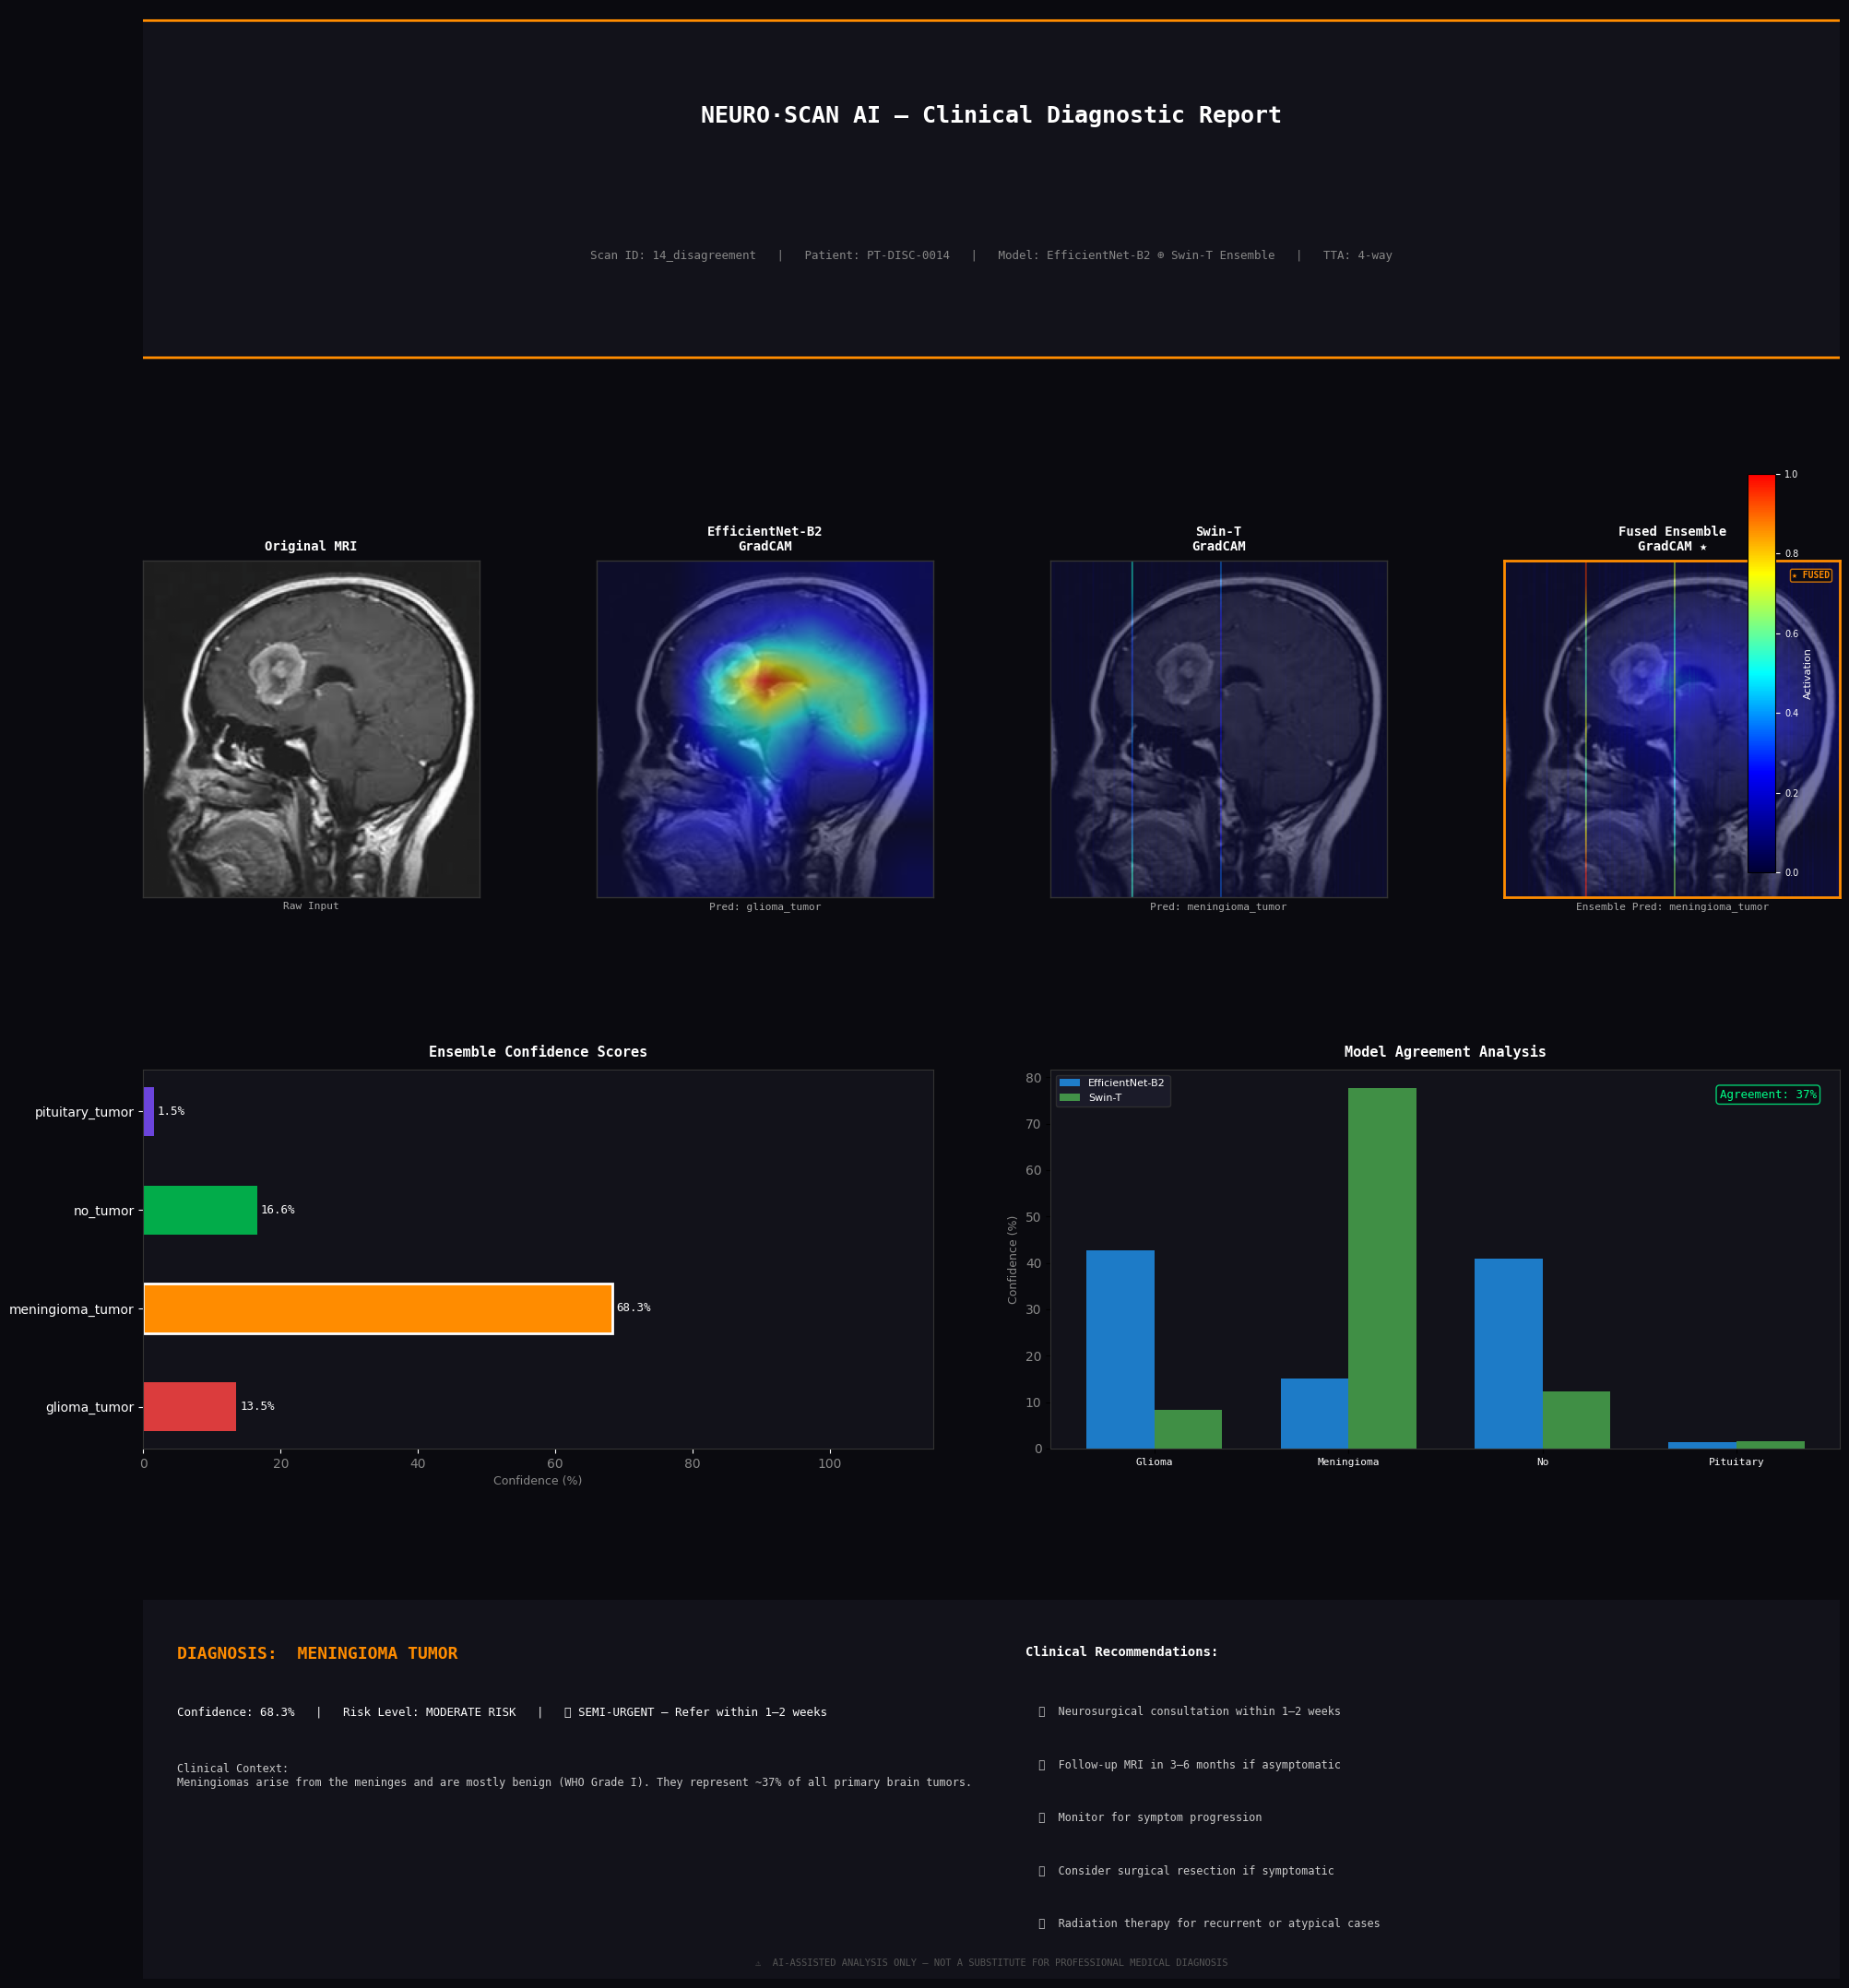


  ✅ Swin-T was correct ✅
  ✅ EfficientNet was wrong ❌
  ✅ Ensemble decision: meningioma_tumor


In [ ]:
#11
# ── Generate clinical reports for sample test scans ───────────────────────────
# Shows 2 examples per class (8 total reports)

print("🏥 Generating Clinical Diagnostic Reports...\n")

results_log = []

# Collect one confident correct prediction per class
class_samples = {cls: [] for cls in merged_aug.classes}

eff_model.eval()
swin_model.eval()

with torch.no_grad():
    for idx in range(len(test_subset)):
        img_tensor, true_label = test_subset[idx]
        inp = img_tensor.unsqueeze(0).to(device)

        eff_p  = torch.softmax(eff_model(inp),  dim=1).cpu().numpy()[0]
        swin_p = torch.softmax(swin_model(inp), dim=1).cpu().numpy()[0]
        ens_p  = best_w * eff_p + (1-best_w) * swin_p

        pred       = ens_p.argmax()
        confidence = ens_p[pred] * 100
        cls_name   = merged_aug.classes[true_label]

        # Collect confident correct predictions (confidence > 70%)
        if pred == true_label and confidence > 70:
            class_samples[cls_name].append((idx, img_tensor, confidence))

# Generate 1 report per class (highest confidence example)
for cls_name in merged_aug.classes:
    if class_samples[cls_name]:
        # Pick highest confidence sample
        samples_sorted = sorted(class_samples[cls_name],
                                 key=lambda x: x[2], reverse=True)
        idx, img_tensor, conf = samples_sorted[0]

        print(f"\n{'='*60}")
        print(f"  Generating report: {cls_name.upper()} (confidence: {conf:.1f}%)")
        print(f"{'='*60}")

        result = generate_clinical_report(
            img_tensor = img_tensor,
            scan_id    = idx,
            patient_id = f'PT-{cls_name[:3].upper()}-{idx:04d}'
        )
        results_log.append(result)

# ── Final summary table ────────────────────────────────────────────────────────
print("\n" + "="*70)
print("  CLINICAL REPORT SUMMARY")
print("="*70)
print(f"  {'Scan ID':<10} {'True Class':<22} {'Confidence':<12} "
      f"{'Agreement':<12} {'Risk'}")
print("-"*70)
for r in results_log:
    print(f"  {r['scan_id']:<10} {r['prediction']:<22} "
          f"{r['confidence']:<12.1f} {r['agreement']:<12.1f} {r['risk']}")
print("="*70)

# ── Also show a disagreement case (where models differ) ───────────────────────
# ── Find a disagreement case (WITHOUT no_grad context) ────────────────────────
print("\n🔍 Finding a case where EfficientNet and Swin-T DISAGREE...")

disagreement_case = None

# Step 1: Find the disagreement case first (inside no_grad is fine here)
with torch.no_grad():
    for idx in range(len(test_subset)):
        img_tensor, true_label = test_subset[idx]
        inp = img_tensor.unsqueeze(0).to(device)

        eff_p  = torch.softmax(eff_model(inp),  dim=1).cpu().numpy()[0]
        swin_p = torch.softmax(swin_model(inp), dim=1).cpu().numpy()[0]

        eff_pred_idx  = eff_p.argmax()
        swin_pred_idx = swin_p.argmax()

        if eff_pred_idx != swin_pred_idx:
            disagreement_case = (idx, img_tensor, true_label,
                                 eff_pred_idx, swin_pred_idx)
            break

# Step 2: Generate report OUTSIDE no_grad (GradCAM needs gradients)
if disagreement_case:
    idx, img_tensor, true_label, eff_pred_idx, swin_pred_idx = disagreement_case

    print(f"  Found disagreement at scan index {idx}")
    print(f"  EfficientNet says : {merged_aug.classes[eff_pred_idx]}")
    print(f"  Swin-T says       : {merged_aug.classes[swin_pred_idx]}")
    print(f"  True label        : {merged_aug.classes[true_label]}")
    print(f"\n  Generating disagreement report...")

    result = generate_clinical_report(
        img_tensor = img_tensor,
        scan_id    = f'{idx}_disagreement',
        patient_id = f'PT-DISC-{idx:04d}'
    )
    print(f"\n  ✅ Swin-T was {'correct ✅' if swin_pred_idx == true_label else 'wrong ❌'}")
    print(f"  ✅ EfficientNet was {'correct ✅' if eff_pred_idx == true_label else 'wrong ❌'}")
    print(f"  ✅ Ensemble decision: {result['prediction']}")
else:
    print("  No disagreement cases found in test set — models agree on everything!")

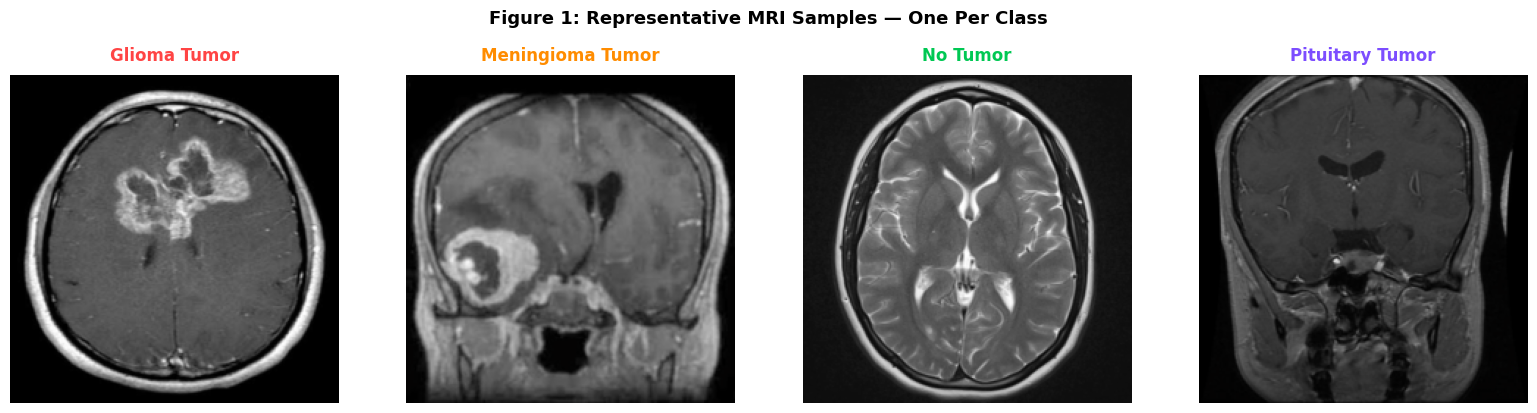

✅ Saved as dataset_samples.png


In [ ]:
#intro dataset
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random

fig, axes = plt.subplots(1, 4, figsize=(16, 4), facecolor='white')

class_names  = merged_aug.classes
class_colors = ['#FF4444', '#FF8C00', '#00C853', '#7C4DFF']

# Pick one sample per class
for col, (cls_name, color) in enumerate(zip(class_names, class_colors)):
    # Find first index belonging to this class
    class_indices = [i for i in range(len(test_subset))
                     if all_targets[test_idx[i]] == merged_aug.class_to_idx[cls_name]]

    sample_idx  = random.choice(class_indices[:10])
    img_tensor, _ = test_subset[sample_idx]

    # Denormalize
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    img  = img_tensor * std + mean
    img  = img.permute(1,2,0).numpy()
    img  = np.clip(img, 0, 1)

    axes[col].imshow(img, cmap='gray')
    axes[col].set_title(
        cls_name.replace('_', ' ').title(),
        fontsize=12, fontweight='bold', color=color, pad=10
    )
    axes[col].axis('off')

    # Colored border per class
    for spine in axes[col].spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(3)

plt.suptitle('Figure 1: Representative MRI Samples — One Per Class',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('dataset_samples.png', dpi=200,
            bbox_inches='tight', facecolor='white')
plt.show()
print("✅ Saved as dataset_samples.png")